# Part 2 — Hands-on Analysis of Security-Level Data

**FE5108 Portfolio Theory and Investments · Fall 2026 class project — practitioner segment**  
Data: Coqueret & Guida (*Machine Learning for Factor Investing*) stock-level extract, MSCI USA index levels, Fama-French factors.

---

### Executive summary

| # | Finding |
|---|---|
| 1 | **The data are usable but not clean.** The universe is steady only from about 2004 to 2016. It breaks in April 1999 (182 names out, 166 in) and collapses after November 2018. Monthly returns reach **+3,018%**. **Pb = 0.50** appears 3.6 times as often as a typical value, most likely a filled value for firms without a meaningful book value. |
| 2 | **The sample is survivor-heavy.** Of 878 stocks present in January 1999, only **10** are gone for good by December 2016. This inflates return levels, above all for cheap, small stocks. |
| 3 | **The market proxy is accurate on timing, not on level.** Correlation with MSCI USA is **0.91** at the correct one-month shift and at most 0.12 at any other. It returned **8.8%/yr** against 5.5%/yr, mostly because rank-based weights are far flatter than real market-cap weights. |
| 4 | **Weighting decides how much value you buy.** Top-20% equal weighting earned the most (**17.1%/yr**) with the highest volatility (**22.0%**) and tracking error (**9.5%**). B/P × cap earned 9.9%/yr with volatility of 17.3% and tracking error of 2.9%. |
| 5 | **Only the cap-aware rule resembles HML.** Correlation with HML is **0.85** for B/P × cap against 0.56 and 0.60 for the others, which also carry a size bet (SMB loading 0.40 and 0.24 against 0.02). |

*Conventions: all fields are in decimals. A panel row dated month t holds the return of month t+1, so portfolio returns are labelled by the month they were earned. The percentile fields run from 0.01 to 1.00 in the file (the brief describes a 100-point scale). All exhibits are also saved in `exports/part2/`.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_hex, to_rgba
import statsmodels.api as sm
from pathlib import Path

from qbstyles import mpl_style

from goldman2 import load_ff3, load_msci_returns, load_stock_panel

# --- house style: same dark qbstyles exhibits as Part 1 ---------------------------
mpl_style(dark=True, minor_ticks=False)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "figure.figsize": (10.5, 5.2),
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "axes.grid": True,
})

# Entities keep one colour throughout. The three value strategies use a palette validated
# for colour-blind separation on the dark panel; the market proxy is neutral context, and
# the MSCI indexes keep their Part 1 colours.
C = {
    "proxy": "#E6ECEF", "p1": "#d95926", "p2": "#199e70", "p3": "#3987e5",
    "msci": "#A6CEE3", "msci_ew": "#FDBF6F", "neutral": "#6F7F87",
}
FIG_BG = to_rgba(plt.rcParams["figure.facecolor"])
AX_BG = to_rgba(plt.rcParams["axes.facecolor"])
PANEL = to_hex([AX_BG[3] * c + (1 - AX_BG[3]) * f for c, f in zip(AX_BG[:3], FIG_BG[:3])])
MUTED = "#9AA7AD"
BLUES = LinearSegmentedColormap.from_list("blues", [PANEL, C["p3"], "#CFE2FA"])

REPO = Path.cwd()
while not (REPO / "pyproject.toml").exists():
    REPO = REPO.parent
EXPORTS = REPO / "exports" / "part2"
EXPORTS.mkdir(parents=True, exist_ok=True)


def save_exhibit(fig, name):
    """Save a print-quality copy for the write-up and display it inline."""
    fig.savefig(EXPORTS / f"{name}.png", dpi=300, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()


def callout(ax, text, xy, xytext, colour="#E6E6E6", fontsize=9.5, ha="center"):
    """Annotation with a masked background, used to write the story onto a chart."""
    ax.annotate(text, xy=xy, xytext=xytext, fontsize=fontsize, color=colour, ha=ha,
                va="center", zorder=6,
                bbox=dict(facecolor=PANEL, edgecolor="none", alpha=0.85, pad=1.5),
                arrowprops=dict(arrowstyle="-", color=colour, lw=0.9, alpha=0.7))


def source_note(fig, text, y=-0.03):
    """Footnote stating what is shown: source, period and universe."""
    fig.text(0.01, y, text, color=MUTED, fontsize=9, ha="left", va="top")


def to_return_month(series):
    """Relabel a panel series from observation month t to the month t+1 its return covers."""
    shifted = series.copy()
    shifted.index = shifted.index + 1
    return shifted


def growth_of_one(returns):
    """Value of $1 invested one month before the first return, on a timestamp index."""
    wealth = (1 + returns).cumprod()
    base = returns.index[0] - 1
    wealth = pd.concat([pd.Series(1.0, index=[base]), wealth])
    wealth.index = pd.PeriodIndex(wealth.index, freq="M").to_timestamp("M")
    return wealth


def performance(returns, rf):
    """Annualised performance of decimal monthly returns (one column per portfolio)."""
    years = len(returns) / 12
    wealth = (1 + returns).cumprod()
    vol = returns.std(ddof=1) * np.sqrt(12)
    return pd.DataFrame({
        "Geometric return": wealth.iloc[-1] ** (1 / years) - 1,
        "Arithmetic return": returns.mean() * 12,
        "Volatility": vol,
        "Sharpe (arithmetic)": returns.sub(rf.reindex(returns.index), axis=0).mean() * 12 / vol,
        "Max drawdown": (wealth / wealth.cummax().clip(lower=1) - 1).min(),
    })


# --- data ------------------------------------------------------------------------
panel = load_stock_panel()                 # decimals; R1M_Usd at date t is the return of t+1
msci = load_msci_returns() / 100           # MSCI USA family, decimals
msci.columns = ["USA", "Value", "Min Vol", "Equal Weighted", "Momentum"]
ff3 = load_ff3() / 100                     # Fama-French factors, decimals

print(f"Panel: {panel['date'].min()} to {panel['date'].max()}, {len(panel):,} stock-months, "
      f"{panel['stock_id'].nunique():,} stocks")
print("Field ranges:", {c: (panel[c].min(), panel[c].max())
                        for c in ["Pb", "Bv", "Mkt_Cap_3M_Usd", "Vol3Y_Usd"]})
print("Duplicate stock-months:", panel.duplicated(["stock_id", "date"]).sum())

Panel: 1998-11 to 2019-03, 283,380 stock-months, 1,207 stocks
Field ranges: {'Pb': (np.float64(0.01), np.float64(1.0)), 'Bv': (np.float64(0.01), np.float64(1.0)), 'Mkt_Cap_3M_Usd': (np.float64(0.01), np.float64(1.0)), 'Vol3Y_Usd': (np.float64(0.01), np.float64(1.0))}
Duplicate stock-months: 0


## 2A · Data cleaning and validation

> **Question.** Check the universe month by month, the return distribution (winsorising at the 99% level) and return coverage. Inspect the P/B field and decide how to treat any odd values. Show how to test that P/B really is market cap over book value.

,Value
Distinct stocks,1207
Smallest monthly universe,552
Largest monthly universe,1196
Apr 1999: stocks entering,166
Apr 1999: stocks leaving,182
...of which return later,182
Stocks present Jan 1999,878
...gone for good before Dec 2016,10
...implied attrition per year,0.06%
All stocks gone for good before Dec 2016,17


,n,mean_cap,max_cap,mean_bv,mean_vol
date,,,,,
2015-01,1192,0.503,1.00,0.504,0.502
2018-11,1109,0.496,1.00,0.499,0.494
2018-12,911,0.451,1.00,0.462,0.506
2019-01,907,0.452,1.00,0.463,0.506
2019-02,555,0.295,0.90,0.325,0.561
2019-03,552,0.336,0.93,0.323,0.562


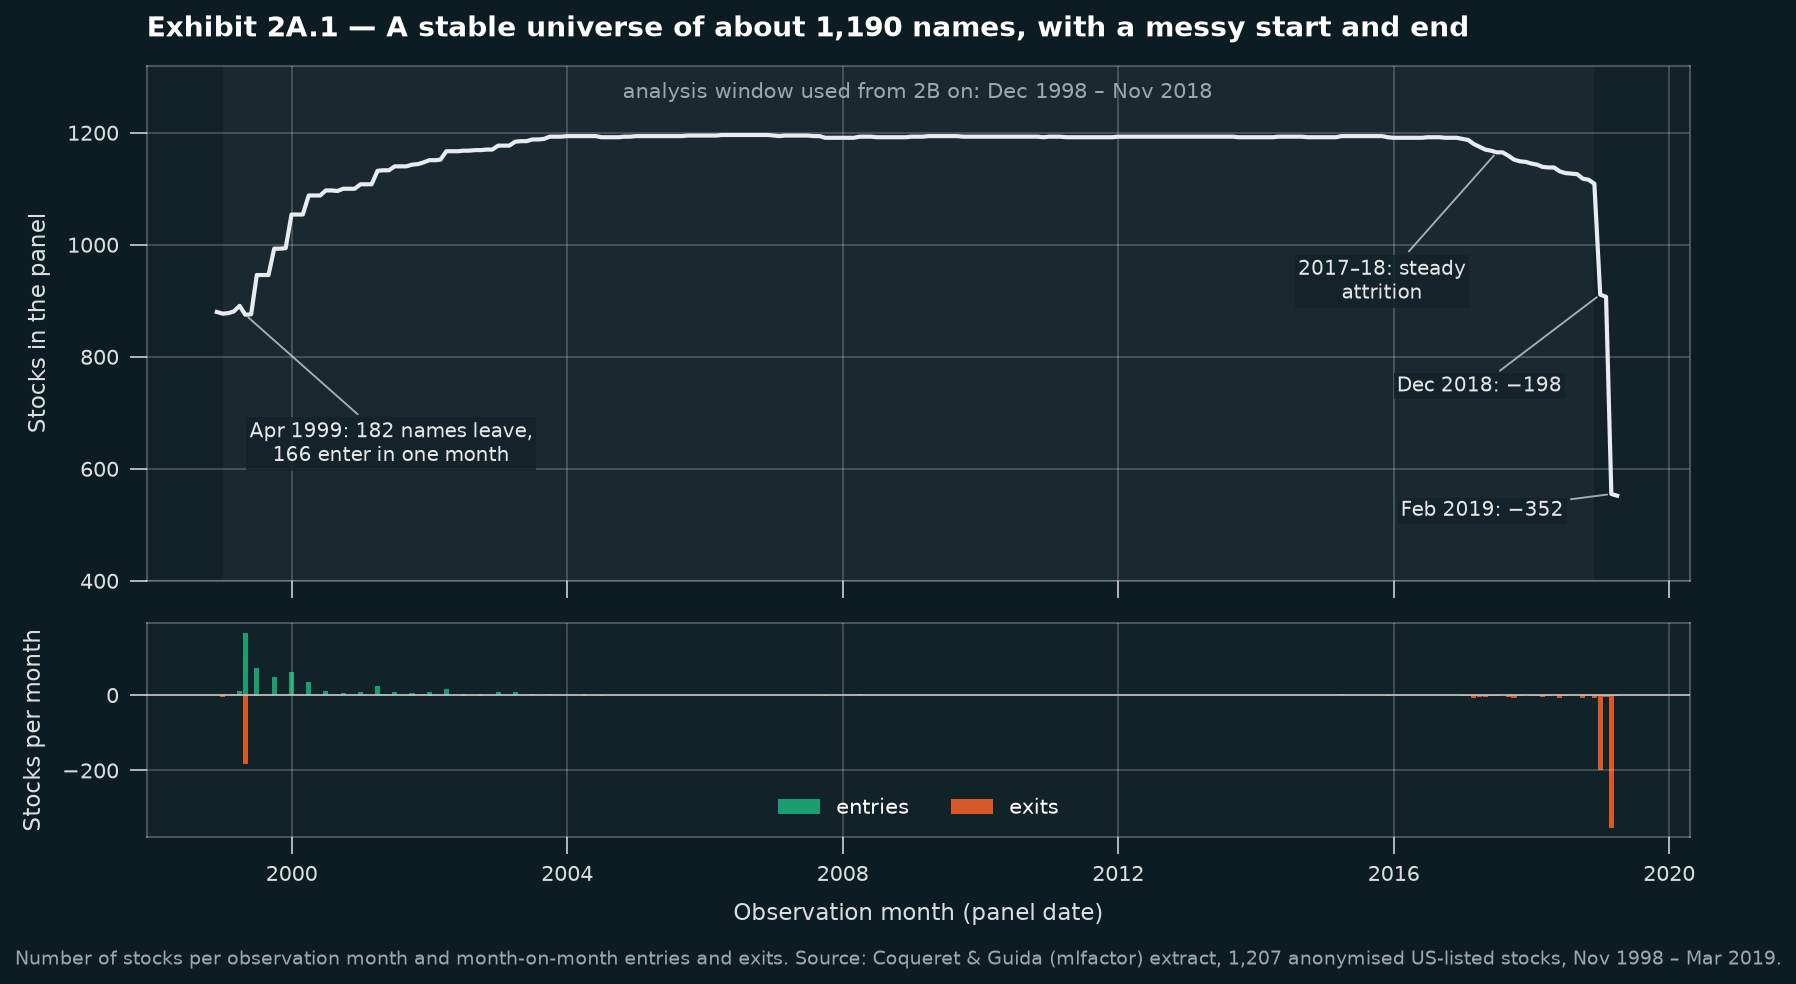

In [2]:
# Universe size and turnover of names, month by month
members = panel.groupby("date")["stock_id"].apply(set)
counts = members.map(len)
months = list(members.index)
flows = pd.DataFrame(
    {"entries": [len(members[b] - members[a]) for a, b in zip(months, months[1:])],
     "exits": [len(members[a] - members[b]) for a, b in zip(months, months[1:])]},
    index=months[1:],
)

life = panel.groupby("stock_id")["date"].agg(["min", "max", "size"])
life["span"] = [(last - first).n + 1 for first, last in zip(life["min"], life["max"])]

# Survivorship: how many of the stocks present in January 1999 leave for good before Dec 2016?
start_names = members[pd.Period("1999-01")]
left_early = (life.loc[list(start_names), "max"] < pd.Period("2016-12")).sum()
annual_attrition = 1 - (1 - left_early / len(start_names)) ** (1 / 18)
april_out = members[pd.Period("1999-03")] - members[pd.Period("1999-04")]

display(pd.DataFrame({
    "Value": [
        life.shape[0], counts.min(), counts.max(),
        flows.loc["1999-04", "entries"], flows.loc["1999-04", "exits"],
        sum(life.loc[s, "max"] > pd.Period("1999-04") for s in april_out),
        len(start_names), left_early, f"{annual_attrition:.2%}",
        (life["max"] < pd.Period("2016-12")).sum(),
    ]},
    index=["Distinct stocks", "Smallest monthly universe", "Largest monthly universe",
           "Apr 1999: stocks entering", "Apr 1999: stocks leaving",
           "...of which return later", "Stocks present Jan 1999",
           "...gone for good before Dec 2016", "...implied attrition per year",
           "All stocks gone for good before Dec 2016"],
).style.set_caption("Table 2A.1 — Universe stability and survivorship checks."))

# Are the percentile fields still uniform (mean 0.50, some stock at 1.00) as the universe breaks?
checks = panel.groupby("date").agg(
    n=("stock_id", "size"), mean_cap=("Mkt_Cap_3M_Usd", "mean"), max_cap=("Mkt_Cap_3M_Usd", "max"),
    mean_bv=("Bv", "mean"), mean_vol=("Vol3Y_Usd", "mean"),
)
display(checks.loc[["2015-01", "2018-11", "2018-12", "2019-01", "2019-02", "2019-03"]].style.format(
    {"mean_cap": "{:.3f}", "max_cap": "{:.2f}", "mean_bv": "{:.3f}", "mean_vol": "{:.3f}"}
).set_caption("Table 2A.2 — Percentile fields lose uniformity once the universe breaks."))

# Exhibit 2A.1 — the universe through time
fig, (ax, ax_flow) = plt.subplots(2, 1, figsize=(11.5, 6.4), sharex=True,
                                  gridspec_kw={"height_ratios": [2.4, 1]})
x = counts.index.to_timestamp("M")
ax.axvspan(pd.Timestamp("1998-12-31"), pd.Timestamp("2018-11-30"), color="#FFFFFF", alpha=0.035, lw=0)
ax.plot(x, counts, color=C["proxy"], lw=2.0)
ax.set_ylim(400, 1320)
ax.set_ylabel("Stocks in the panel")
ax.set_title("Exhibit 2A.1 — A stable universe of about 1,190 names, with a messy start and end",
             loc="left", fontsize=13.5)
ax.text(pd.Timestamp("2009-01-31"), 1262, "analysis window used from 2B on: Dec 1998 – Nov 2018",
        color=MUTED, fontsize=10, ha="center")
for period, label, offset in [
    ("1999-04", "Apr 1999: 182 names leave,\n166 enter in one month", (70, -62)),
    ("2017-06", "2017–18: steady\nattrition", (-55, -62)),
    ("2018-12", "Dec 2018: −198", (-58, -44)),
    ("2019-02", "Feb 2019: −352", (-62, -8)),
]:
    stamp = pd.Period(period).to_timestamp("M")
    ax.annotate(label, xy=(stamp, counts[period]), xytext=offset, textcoords="offset points",
                fontsize=9.5, color="#E6E6E6", ha="center", va="center", zorder=6,
                bbox=dict(facecolor=PANEL, edgecolor="none", alpha=0.85, pad=1.5),
                arrowprops=dict(arrowstyle="-", color="#E6E6E6", lw=0.9, alpha=0.7))
xf = flows.index.to_timestamp("M")
ax_flow.bar(xf, flows["entries"], width=28, color=C["p2"], label="entries")
ax_flow.bar(xf, -flows["exits"], width=28, color=C["p1"], label="exits")
ax_flow.axhline(0, color="#C0C0C0", lw=0.8)
ax_flow.set_ylabel("Stocks per month")
ax_flow.set_xlabel("Observation month (panel date)")
ax_flow.legend(loc="lower center", ncol=2)
fig.tight_layout()
source_note(fig, "Number of stocks per observation month and month-on-month entries and exits. Source: Coqueret & Guida "
                 "(mlfactor) extract, 1,207 anonymised US-listed stocks, Nov 1998 – Mar 2019.", y=0.0)
save_exhibit(fig, "2a_universe")

**Comment — universe.** The universe is not consistently defined; it is stable only from about 2004 to 2016, at about 1,190 names.

* **Questionable months.** April 1999 stands out: 182 stocks vanish and 166 appear in one month. All 182 come back later, 170 of them by March 2000 in quarterly steps, which suggests a data-feed break and not real delistings.
* **The end of the sample.** Names fall away through 2017–18, then by 198 in December 2018 and 352 in February 2019. The percentile fields stop being uniform at that point (Table 2A.2): by February 2019 the average cap percentile is 0.30 and no stock is above 0.90, so the survivors are mostly small. The window used from 2B on ends before these two cliffs.
* **Survivorship.** Only 10 of the 878 stocks present in January 1999 leave for good before December 2016, about 0.06% a year. Real listed companies disappear through mergers and delistings at several percent a year. The list looks chosen with hindsight, which inflates return levels; we return to this in 2B and 2C.

,Mean %/mo,Median %/mo,Std %/mo,Min %,Max %,Skew,Excess kurtosis
Raw,1.26,1.10,17.79,-92.20,"3,017.60",58.76,"7,610.06"
Winsorised,1.12,1.10,11.01,-62.50,147.32,0.57,7.62


Rows clipped: 2.02% (low 1.01%, high 1.01%); average cut-offs -26.0% / 30.3%


,stock_id,date,R1M_Usd,Mkt_Cap_3M_Usd,Pb
275684,885,2018-07,3017.6%,0.01,0.01
151741,221,2009-11,2723.3%,0.14,0.19
261766,663,2017-07,2443.0%,0.01,0.01
29649,212,2001-04,1955.6%,0.09,0.01
178072,317,2011-09,1691.3%,0.62,0.50


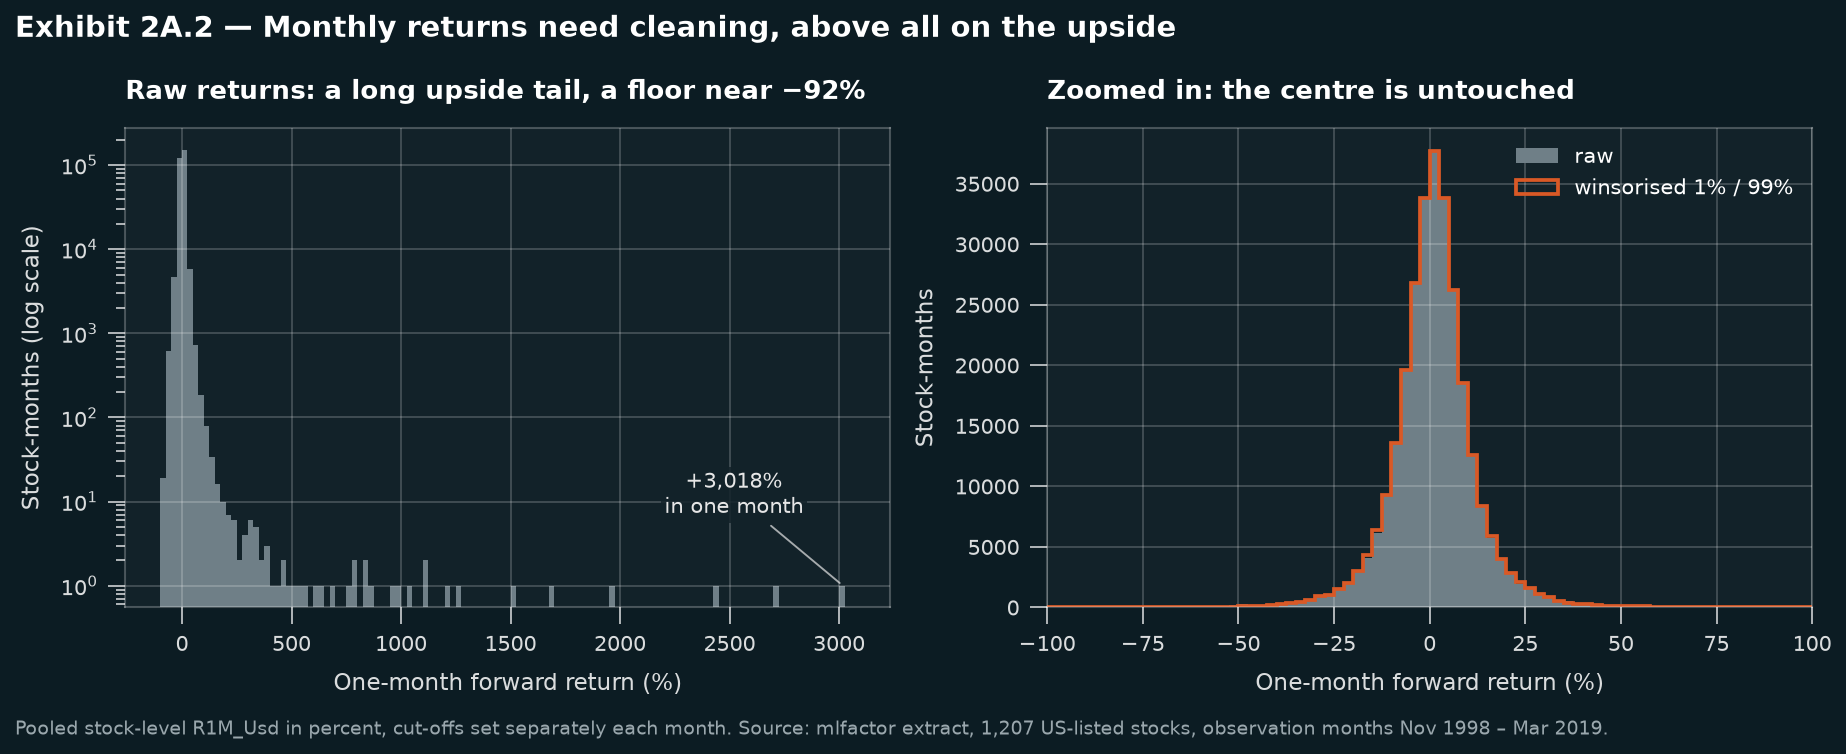

In [3]:
# Per-month two-sided winsorisation at the 1st and 99th percentiles
by_month = panel.groupby("date")["R1M_Usd"]
panel["lower"] = by_month.transform(lambda s: s.quantile(0.01))
panel["upper"] = by_month.transform(lambda s: s.quantile(0.99))
panel["ret"] = panel["R1M_Usd"].clip(panel["lower"], panel["upper"])


def shape(series):
    return {"Mean %/mo": series.mean() * 100, "Median %/mo": series.median() * 100,
            "Std %/mo": series.std() * 100, "Min %": series.min() * 100, "Max %": series.max() * 100,
            "Skew": series.skew(), "Excess kurtosis": series.kurt()}


display(pd.DataFrame({"Raw": shape(panel["R1M_Usd"]), "Winsorised": shape(panel["ret"])}).T.style.format(
    "{:,.2f}").set_caption("Table 2A.3 — Pooled monthly stock returns before and after winsorising."))
print(f"Rows clipped: {(panel['ret'] != panel['R1M_Usd']).mean():.2%} "
      f"(low {(panel['R1M_Usd'] < panel['lower']).mean():.2%}, high {(panel['R1M_Usd'] > panel['upper']).mean():.2%}); "
      f"average cut-offs {panel.groupby('date')['lower'].first().mean():.1%} / "
      f"{panel.groupby('date')['upper'].first().mean():.1%}")
display(panel.nlargest(5, "R1M_Usd")[["stock_id", "date", "R1M_Usd", "Mkt_Cap_3M_Usd", "Pb"]].style.format(
    {"R1M_Usd": "{:.1%}", "Mkt_Cap_3M_Usd": "{:.2f}", "Pb": "{:.2f}"}, precision=0
).set_caption("Table 2A.4 — Largest raw returns (date is the observation month; the return is for the next month)."))

# Exhibit 2A.2 — the raw tail, and what winsorising removes
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8))
axes[0].hist(panel["R1M_Usd"] * 100, bins=np.arange(-100, 3100, 25), color=C["neutral"], lw=0)
axes[0].set_yscale("log")
axes[0].set_xlabel("One-month forward return (%)")
axes[0].set_ylabel("Stock-months (log scale)")
axes[0].set_title("Raw returns: a long upside tail, a floor near −92%", loc="left", fontsize=12.5)
callout(axes[0], f"+{panel['R1M_Usd'].max():,.0%}\nin one month", xy=(panel["R1M_Usd"].max() * 100, 1),
        xytext=(2520, 12), fontsize=10)
bins = np.arange(-100, 101, 2.5)
axes[1].hist(panel["R1M_Usd"] * 100, bins=bins, color=C["neutral"], lw=0, label="raw")
axes[1].hist(panel["ret"] * 100, bins=bins, histtype="step", color=C["p1"], lw=1.8, label="winsorised 1% / 99%")
axes[1].set_xlim(-100, 100)
axes[1].set_xlabel("One-month forward return (%)")
axes[1].set_ylabel("Stock-months")
axes[1].set_title("Zoomed in: the centre is untouched", loc="left", fontsize=12.5)
axes[1].legend(loc="upper right")
fig.suptitle("Exhibit 2A.2 — Monthly returns need cleaning, above all on the upside",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Pooled stock-level R1M_Usd in percent, cut-offs set separately each month. Source: mlfactor extract, "
                 "1,207 US-listed stocks, observation months Nov 1998 – Mar 2019.", y=0.0)
save_exhibit(fig, "2a_returns")

**Comment — returns.** There are outliers on both sides, but the upside is far more extreme: the maximum is +3,018% in a month against a minimum of −92.2%, with skew of 59 and excess kurtosis of 7,610. Three of the five largest returns come from stocks in the bottom decile of market cap and the bottom percentile of P/B, exactly the stocks a value portfolio buys.

We read "winsorising at the 99% level" as capping each month's cross-section at its own 1st and 99th percentiles. This changes 2.0% of rows, at average cut-offs of −26.0% and +30.3%. The monthly standard deviation falls from 17.8% to 11.0%, and the mean from 1.26% to 1.12%. Winsorised returns are used from here on. Some of the removed gains are probably real, so Table 2C.3 also reports raw results.

Missing R1M_Usd values in the file: 0
Stocks with a gap in their history: 205, missing stock-months: 1,514
Live coverage under 99%: 1999-04 to 2000-05; lowest 82.8% in 1999-04
Exact-zero returns: 0.66% of rows, highest month 2.1% (1999-10); stocks with 3+ zero months in a row: 2, longest run 13


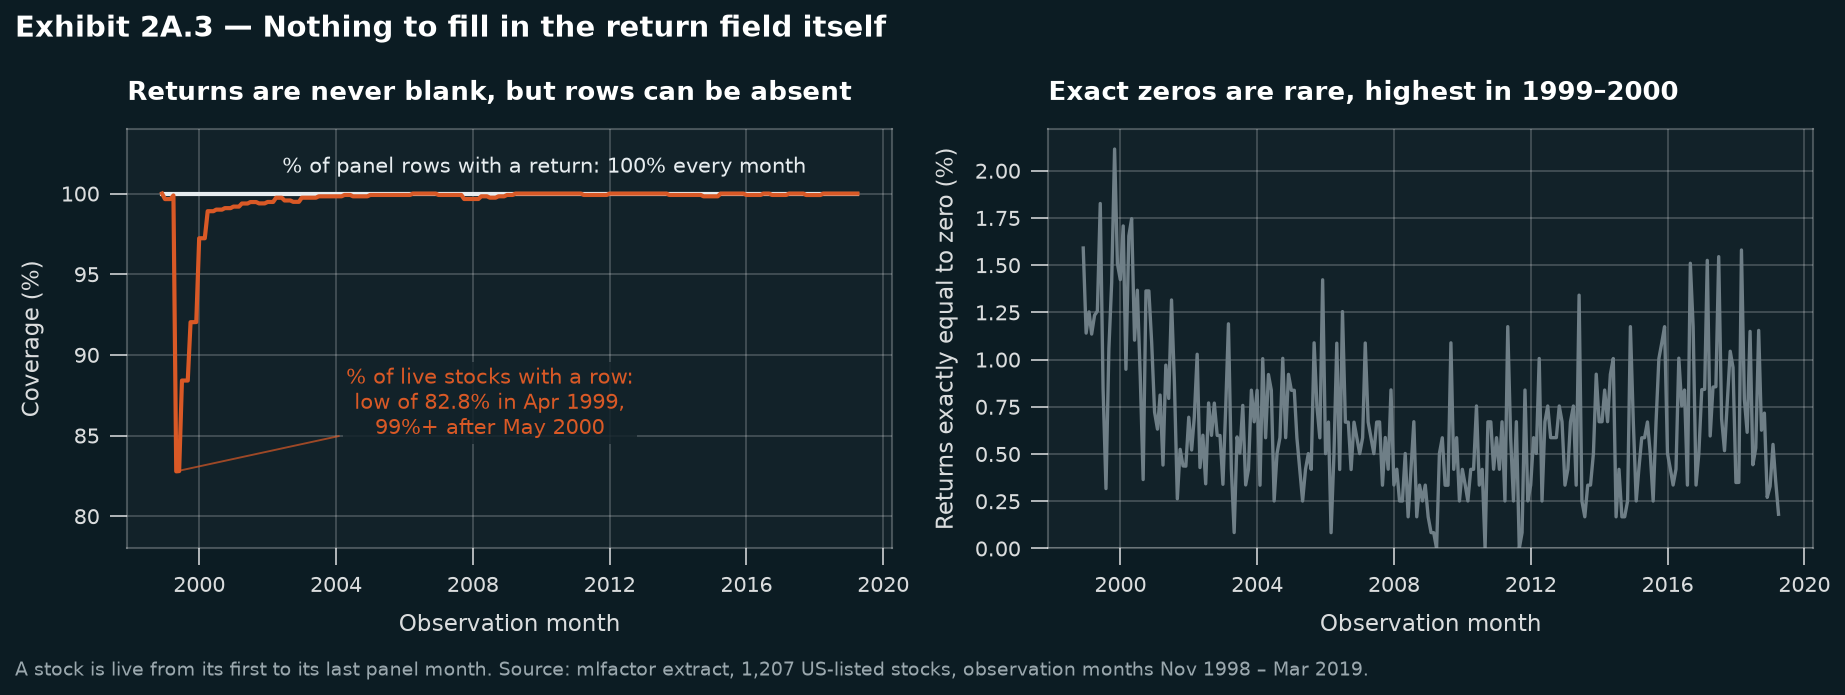

In [4]:
# Two coverage measures: non-missing values in the file, and rows present among stocks already/still alive
field_coverage = panel.groupby("date")["R1M_Usd"].apply(lambda s: s.notna().mean())
alive = pd.Series({d: ((life["min"] <= d) & (life["max"] >= d)).sum() for d in counts.index})
live_coverage = counts / alive
zero_share = panel.groupby("date")["R1M_Usd"].apply(lambda s: (s == 0).mean())

ordered = panel.sort_values(["stock_id", "date"]).assign(zero=lambda d: d["R1M_Usd"] == 0)
zero_runs = ordered.groupby("stock_id")["zero"].apply(lambda s: s.groupby((~s).cumsum()).cumsum().max())
gap_stocks = life[life["span"] != life["size"]]

print(f"Missing R1M_Usd values in the file: {panel['R1M_Usd'].isna().sum()}")
print(f"Stocks with a gap in their history: {len(gap_stocks)}, missing stock-months: "
      f"{(gap_stocks['span'] - gap_stocks['size']).sum():,}")
below = live_coverage[live_coverage < 0.99]
print(f"Live coverage under 99%: {below.index.min()} to {below.index.max()}; "
      f"lowest {live_coverage.min():.1%} in {live_coverage.idxmin()}")
print(f"Exact-zero returns: {(panel['R1M_Usd'] == 0).mean():.2%} of rows, highest month "
      f"{zero_share.max():.1%} ({zero_share.idxmax()}); stocks with 3+ zero months in a row: "
      f"{(zero_runs >= 3).sum()}, longest run {zero_runs.max()}")

# Exhibit 2A.3 — coverage of the return field
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4))
x = counts.index.to_timestamp("M")
axes[0].plot(x, field_coverage * 100, color=C["proxy"], lw=2.0)
axes[0].plot(x, live_coverage * 100, color=C["p1"], lw=2.0)
axes[0].set_ylim(78, 104)
axes[0].set_ylabel("Coverage (%)")
axes[0].set_xlabel("Observation month")
axes[0].set_title("Returns are never blank, but rows can be absent", loc="left", fontsize=12.5)
axes[0].text(pd.Timestamp("2010-01-31"), 101.3, "% of panel rows with a return: 100% every month",
             color=C["proxy"], fontsize=10, ha="center")
callout(axes[0], f"% of live stocks with a row:\nlow of {live_coverage.min():.1%} in Apr 1999,\n99%+ after May 2000",
        xy=(pd.Timestamp("1999-04-30"), live_coverage.min() * 100),
        xytext=(pd.Timestamp("2008-06-30"), 87), colour=C["p1"], fontsize=10)
axes[1].plot(x, zero_share * 100, color=C["neutral"], lw=1.6)
axes[1].set_ylabel("Returns exactly equal to zero (%)")
axes[1].set_xlabel("Observation month")
axes[1].set_ylim(0, None)
axes[1].set_title("Exact zeros are rare, highest in 1999–2000", loc="left", fontsize=12.5)
fig.suptitle("Exhibit 2A.3 — Nothing to fill in the return field itself", fontsize=14, fontweight="bold",
             x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "A stock is live from its first to its last panel month. Source: mlfactor extract, 1,207 US-listed stocks, "
                 "observation months Nov 1998 – Mar 2019.", y=0.0)
save_exhibit(fig, "2a_coverage")

**Comment — coverage.** `R1M_Usd` is never blank, so field coverage is 100% every month. The gaps are whole rows instead: 205 stocks miss 1,514 stock-months inside their history, 89% of them from the stocks that left in April 1999, taking coverage of live stocks to 82.8% at its low.

**Treatment.** A stock without a return that month is left out, and the remaining weights are rescaled to sum to one. A zero fill would invent a flat month, and any fill needs characteristics we also lack for those rows. The cost is that a stock which truly delisted at a large loss drops out without that loss, which adds to the survivorship bias.

Exact zeros are 0.66% of rows, peaking at 2.1% in October 1999. With returns rounded to three decimals many will be genuine. Only two stocks show three or more zero months in a row (longest 13), which looks like stale pricing but is too rare to matter, so they are kept.

Rows at Pb = 0.50: 10,197; typical grid value: 2,802; excess: 7,395 (2.6% of rows)
Pb = 0.50 rows with Bv <= 0.03: 5,720 (56%); in top volatility decile: 25%
Bv <= 0.03 rows: 66% at Pb = 0.50, 24% above Pb = 0.90
Spike rows per month: 41 (median); distinct stocks ever affected: 717


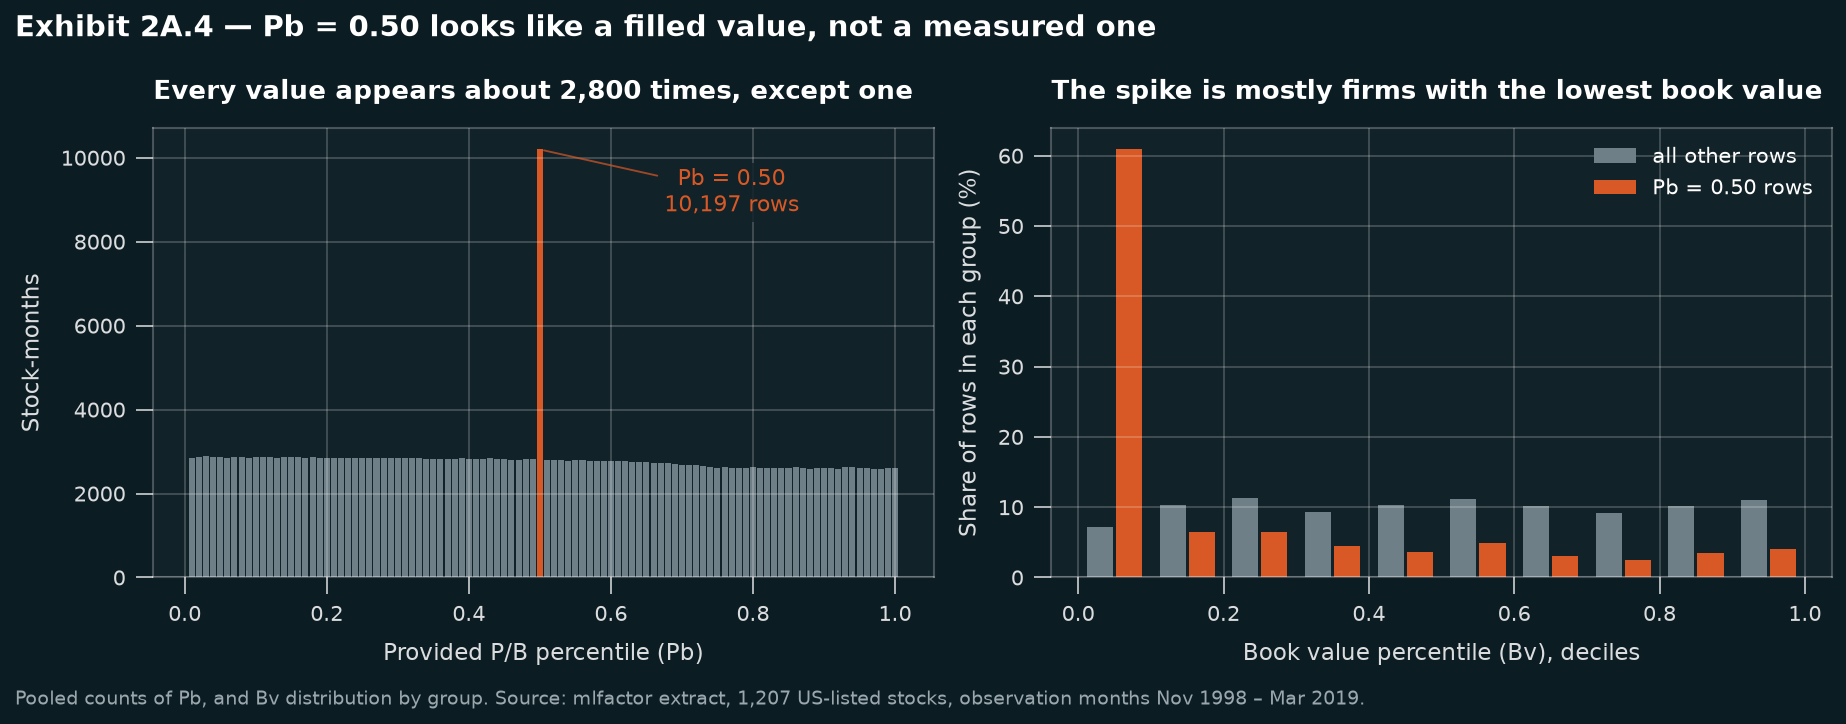

In [5]:
# The P/B percentile should be flat across its 100 grid values. It is not.
pb_counts = panel["Pb"].round(2).value_counts().sort_index()
spike = panel["Pb"].eq(0.5)
typical = pb_counts.drop(0.5).median()
print(f"Rows at Pb = 0.50: {spike.sum():,}; typical grid value: {typical:,.0f}; "
      f"excess: {spike.sum() - typical:,.0f} ({(spike.sum() - typical) / len(panel):.1%} of rows)")
print(f"Pb = 0.50 rows with Bv <= 0.03: {(spike & panel['Bv'].le(0.03)).sum():,} "
      f"({(spike & panel['Bv'].le(0.03)).sum() / spike.sum():.0%}); "
      f"in top volatility decile: {panel.loc[spike, 'Vol3Y_Usd'].gt(0.9).mean():.0%}")
low_book = panel[panel["Bv"].le(0.03)]
print(f"Bv <= 0.03 rows: {low_book['Pb'].eq(0.5).mean():.0%} at Pb = 0.50, "
      f"{low_book['Pb'].gt(0.9).mean():.0%} above Pb = 0.90")
print(f"Spike rows per month: {spike.groupby(panel['date']).sum().median():.0f} (median); "
      f"distinct stocks ever affected: {panel.loc[spike, 'stock_id'].nunique()}")

# Exhibit 2A.4 — the spike and what sits behind it
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6))
colours = [C["p1"] if v == 0.5 else C["neutral"] for v in pb_counts.index]
axes[0].bar(pb_counts.index, pb_counts, width=0.0085, color=colours)
axes[0].set_xlabel("Provided P/B percentile (Pb)")
axes[0].set_ylabel("Stock-months")
axes[0].set_title("Every value appears about 2,800 times, except one", loc="left", fontsize=12.5)
callout(axes[0], f"Pb = 0.50\n{spike.sum():,} rows", xy=(0.5, spike.sum()), xytext=(0.77, spike.sum() * 0.9),
        colour=C["p1"], fontsize=10.5)
edges = np.arange(0, 1.01, 0.1)
share_spike = np.histogram(panel.loc[spike, "Bv"], bins=edges)[0] / spike.sum() * 100
share_rest = np.histogram(panel.loc[~spike, "Bv"], bins=edges)[0] / (~spike).sum() * 100
centres = edges[:-1] + 0.05
axes[1].bar(centres - 0.02, share_rest, width=0.036, color=C["neutral"], label="all other rows")
axes[1].bar(centres + 0.02, share_spike, width=0.036, color=C["p1"], label="Pb = 0.50 rows")
axes[1].set_xlabel("Book value percentile (Bv), deciles")
axes[1].set_ylabel("Share of rows in each group (%)")
axes[1].set_title("The spike is mostly firms with the lowest book value", loc="left", fontsize=12.5)
axes[1].legend(loc="upper right")
fig.suptitle("Exhibit 2A.4 — Pb = 0.50 looks like a filled value, not a measured one", fontsize=14, fontweight="bold",
             x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Pooled counts of Pb, and Bv distribution by group. Source: mlfactor extract, 1,207 US-listed stocks, "
                 "observation months Nov 1998 – Mar 2019.", y=0.0)
save_exhibit(fig, "2a_pb_spike")

**Comment — the P/B spike.** Pb = 0.50 appears 10,197 times against about 2,800 for a typical value, an excess of about 7,400 rows (2.6% of the data). About 41 rows a month sit at this value, across 717 stocks in all. These rows differ from the rest: 56% have Bv ≤ 0.03, and 25% sit in the top volatility decile. Conversely, 66% of all rows with Bv ≤ 0.03 have Pb = 0.50.

**Interpretation.** The likeliest cause is firms with negative or near-zero book equity, whose P/B is not meaningful and has been set to the cross-sectional median. This is our inference: the data documentation does not describe a fill rule. Fama and French require positive book equity for their value sorts, so these firms would not be in HML at all.

**Treatment.** All Pb = 0.50 rows are excluded from the three value portfolios, but stay in the market proxy, which does not use P/B. Treating such a firm as averagely priced would be wrong. The rule also removes about 2,800 genuinely median rows, which carry little value signal, and Table 2C.3 shows the choice moves winsorised returns by at most 0.1 point a year (0.5 on raw returns).

Spearman(Pb, cap − book) on all rows: 0.867


,"Spearman(Pb, cap − book)","Spearman(Pb, cap)","Spearman(Pb, book)",Slope on cap,Slope on book
mean,0.89,0.36,-0.08,1.64,-1.51
min,0.71,0.24,-0.33,1.21,-1.77
max,0.93,0.53,0.11,1.83,-1.08


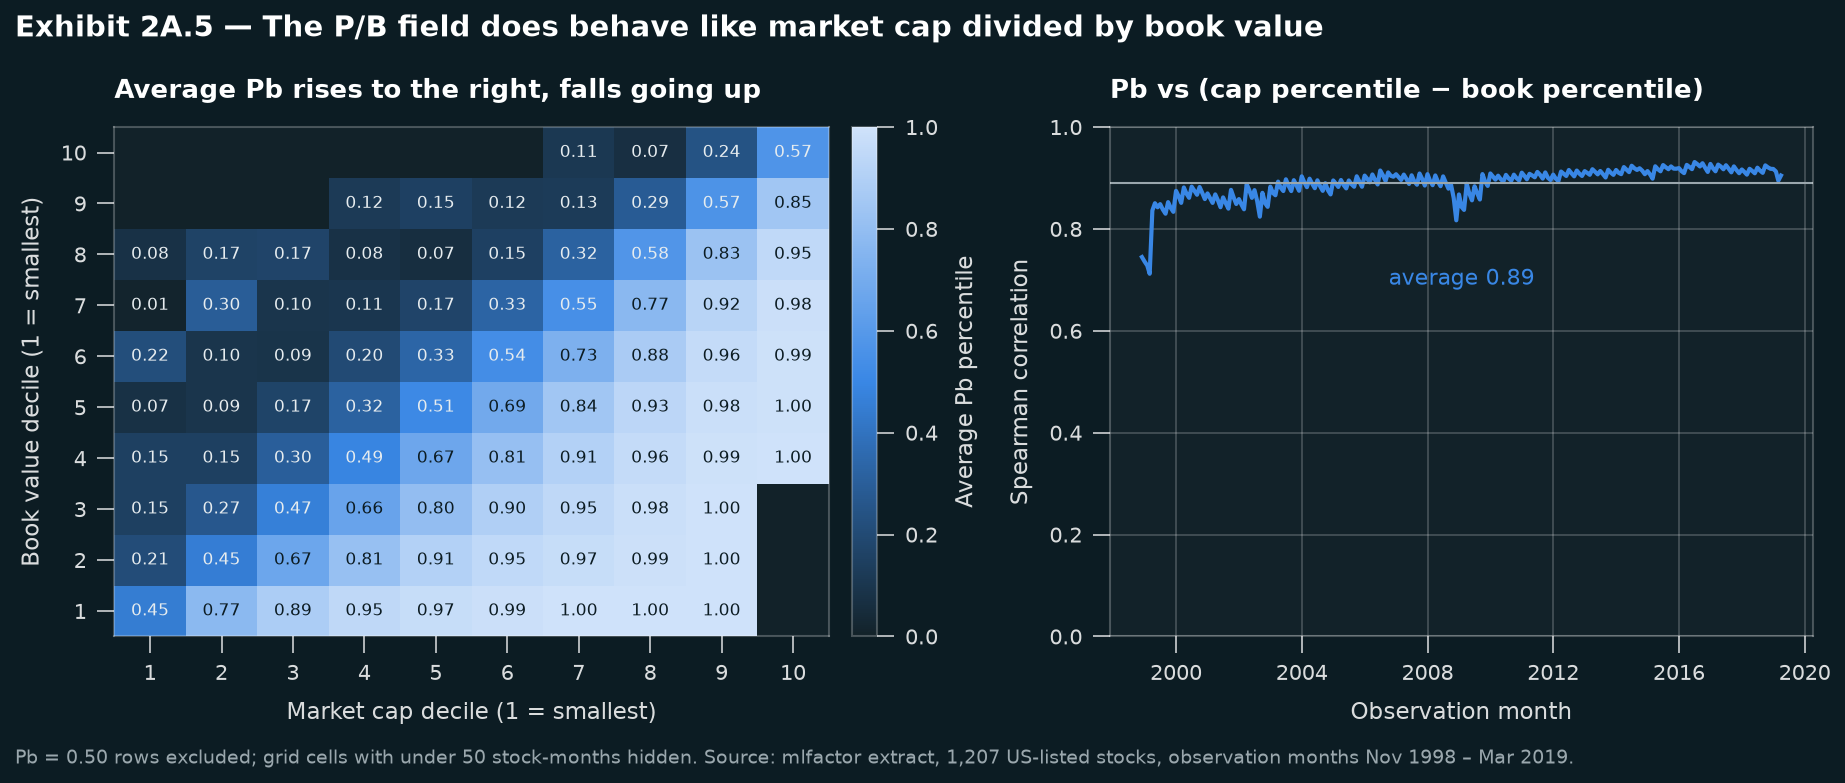

In [6]:
# If P/B = market cap / book value, its percentile must rise with cap and fall with book value
measured = panel[~spike]


def monthly_check(frame):
    gap = frame["Mkt_Cap_3M_Usd"] - frame["Bv"]
    fit = np.linalg.lstsq(np.column_stack([np.ones(len(frame)), frame["Mkt_Cap_3M_Usd"], frame["Bv"]]),
                          frame["Pb"].to_numpy(), rcond=None)[0]
    return pd.Series({"Spearman(Pb, cap − book)": frame["Pb"].corr(gap, method="spearman"),
                      "Spearman(Pb, cap)": frame["Pb"].corr(frame["Mkt_Cap_3M_Usd"], method="spearman"),
                      "Spearman(Pb, book)": frame["Pb"].corr(frame["Bv"], method="spearman"),
                      "Slope on cap": fit[1], "Slope on book": fit[2]})


sanity_all = panel.groupby("date")[["Pb", "Bv", "Mkt_Cap_3M_Usd"]].apply(monthly_check)
sanity = measured.groupby("date")[["Pb", "Bv", "Mkt_Cap_3M_Usd"]].apply(monthly_check)
print(f"Spearman(Pb, cap − book) on all rows: {sanity_all.iloc[:, 0].mean():.3f}")
display(sanity.agg(["mean", "min", "max"]).style.format("{:.2f}").set_caption(
    "Table 2A.5 — Month-by-month cross-sectional checks, excluding Pb = 0.50 rows."))

deciles = measured.assign(cap_bin=np.ceil(measured["Mkt_Cap_3M_Usd"] * 10).astype(int),
                          bv_bin=np.ceil(measured["Bv"] * 10).astype(int))
grid = deciles.pivot_table(index="bv_bin", columns="cap_bin", values="Pb", aggfunc="mean")
cell_counts = deciles.pivot_table(index="bv_bin", columns="cap_bin", values="Pb", aggfunc="size")
grid = grid.where(cell_counts >= 50)  # hide cells too thin to read

# Exhibit 2A.5 — P/B behaves like market cap over book value
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.0), gridspec_kw={"width_ratios": [1.1, 1]})
image = axes[0].imshow(grid, origin="lower", cmap=BLUES, vmin=0, vmax=1, aspect="auto", extent=(0.5, 10.5, 0.5, 10.5))
for row, bv_bin in enumerate(grid.index):
    for col, cap_bin in enumerate(grid.columns):
        value = grid.iloc[row, col]
        if pd.notna(value):
            axes[0].text(cap_bin, bv_bin, f"{value:.2f}", ha="center", va="center", fontsize=8,
                         color="#0C1C23" if value > 0.62 else "#E6ECEF")
axes[0].set_xticks(range(1, 11))
axes[0].set_yticks(range(1, 11))
axes[0].grid(False)
axes[0].set_xlabel("Market cap decile (1 = smallest)")
axes[0].set_ylabel("Book value decile (1 = smallest)")
axes[0].set_title("Average Pb rises to the right, falls going up", loc="left", fontsize=12.5)
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.03, label="Average Pb percentile")
x = sanity.index.to_timestamp("M")
axes[1].plot(x, sanity.iloc[:, 0], color=C["p3"], lw=2.0)
axes[1].axhline(sanity.iloc[:, 0].mean(), color=MUTED, lw=1.0)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Observation month")
axes[1].set_ylabel("Spearman correlation")
axes[1].set_title("Pb vs (cap percentile − book percentile)", loc="left", fontsize=12.5)
axes[1].text(pd.Timestamp("2009-01-31"), sanity.iloc[:, 0].mean() - 0.2,
             f"average {sanity.iloc[:, 0].mean():.2f}", color=C["p3"], fontsize=10.5, ha="center")
fig.suptitle("Exhibit 2A.5 — The P/B field does behave like market cap divided by book value", fontsize=14,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Pb = 0.50 rows excluded; grid cells with under 50 stock-months hidden. Source: mlfactor extract, 1,207 "
                 "US-listed stocks, observation months Nov 1998 – Mar 2019.", y=0.0)
save_exhibit(fig, "2a_pb_sanity")

**Comment — is P/B really cap over book?** Percentiles cannot rebuild the ratio, but since log(P/B) = log(cap) − log(book), the field must rise with cap and fall with book value.

It does. Holding one input fixed, average Pb climbs along the other, apart from thinly populated cells at the top left (Exhibit 2A.5). Each month's cross-sectional slopes always have the right signs: +1.21 to +1.83 on cap and −1.77 to −1.08 on book. The Spearman correlation with (cap percentile − book percentile) averages **0.89**, against 0.36 for cap alone and −0.08 for book alone. Book alone looks weak only because large firms also have large books.

The match is not exact, since the cap field is a three-month average and percentiles distort distances. The weakest readings (0.71) are in early 1999, the same period as the universe break.

## 2B · Rules-based portfolio construction: broad market

> **Question.** Using December 1998 – November 2018, weight stocks by their standardised market cap to approximate the cap-weighted market. Compare with MSCI USA, aligning periods properly, and show how you might gain confidence in the universe and the return data.

Characteristics known at the end of month *t* set the weights, which earn `R1M_Usd`, the return of month *t+1*. Returns therefore cover January 1999 – December 2018 (240 months) without look-ahead.

,Correlation,Beta,R²,Alpha %/yr,Tracking error %/yr,Same sign %
MSCI USA,0.91,1.03,0.82,3.22,6.93,89.58
MSCI USA Equal Weighted,0.96,0.95,0.93,1.40,4.42,90.42
FF total market (Mkt−RF + RF),0.92,1.01,0.85,2.65,6.49,90.00


,Geometric return,Arithmetic return,Volatility,Sharpe (arithmetic),Max drawdown
Market proxy,8.8%,9.8%,16.5%,0.49,-51.5%
MSCI USA,5.5%,6.4%,14.6%,0.32,-50.6%
MSCI USA Equal Weighted,7.7%,8.8%,16.7%,0.42,-54.8%
FF total market (Mkt−RF + RF),6.1%,7.1%,15.0%,0.36,-50.4%


,1999–2006,2007–2012,2013–2018
Market proxy,11.1%,4.6%,10.0%
MSCI USA,3.0%,2.5%,12.0%
MSCI USA Equal Weighted,8.1%,3.8%,11.1%
FF total market (Mkt−RF + RF),4.3%,2.8%,12.2%


Proxy on winsorised vs raw returns: 8.77% vs 8.91%; corr with MSCI USA raw 0.907
Proxy excess return on FF3: {'const': 0.001, 'Mkt-RF': 0.997, 'SMB': 0.196, 'HML': 0.412}
Nov 2018 proxy weights: largest 0.182%, smallest 0.002%, effective stocks 826 of 1109


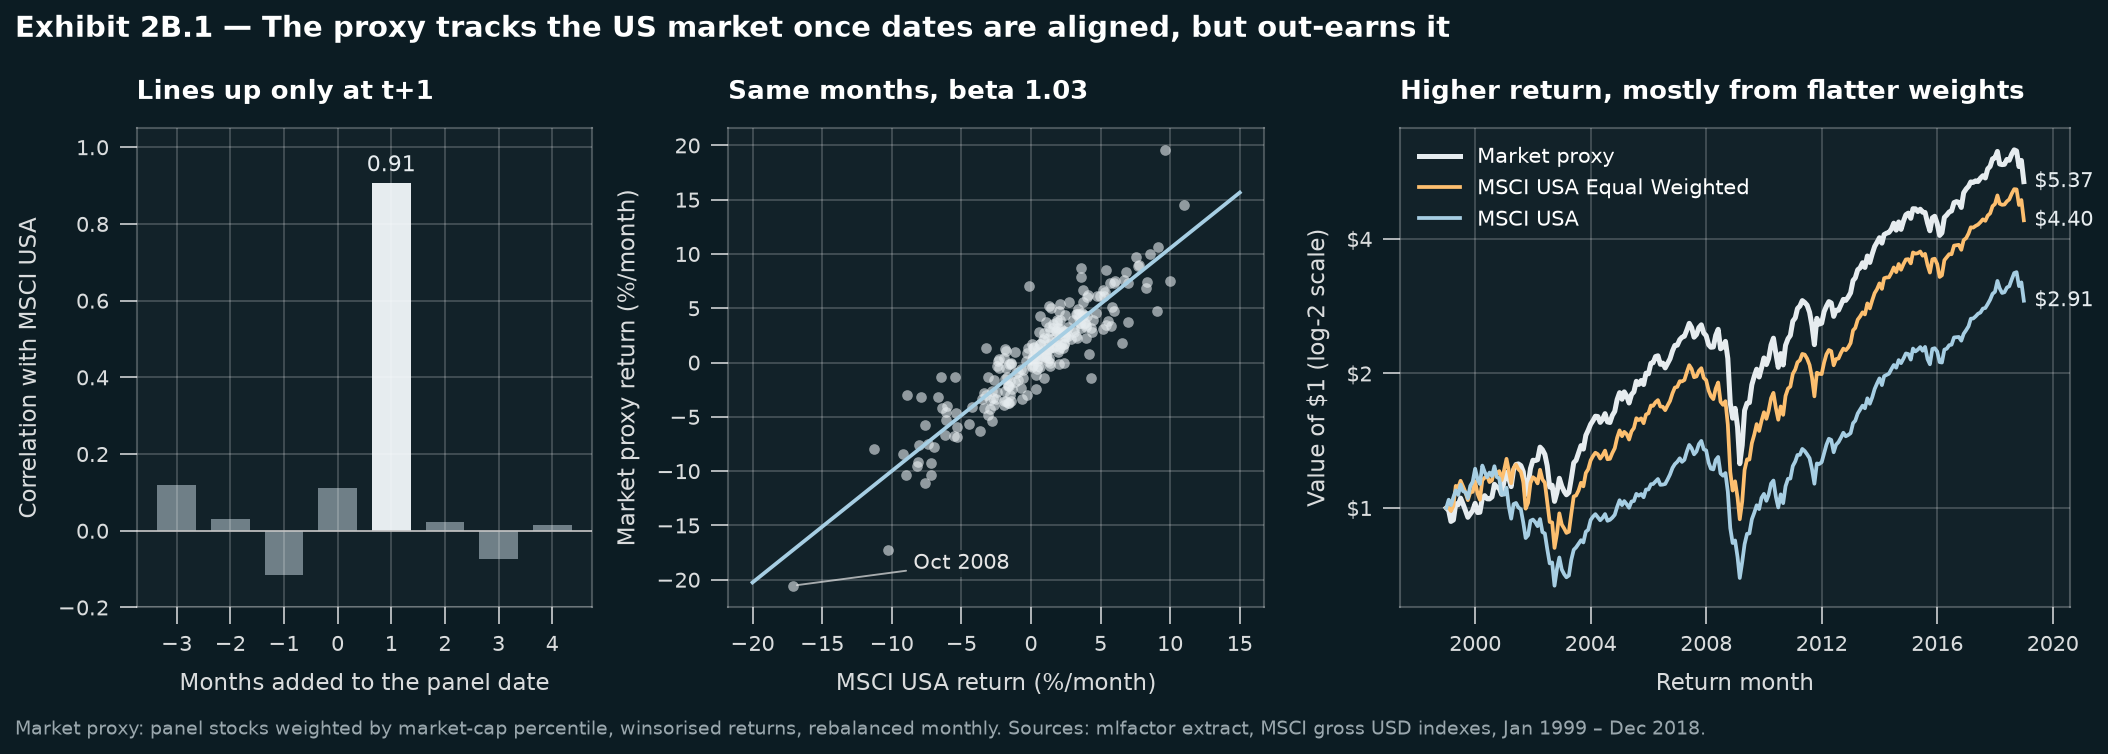

In [7]:
# Analysis window: features known at Dec 1998 – Nov 2018, so returns cover Jan 1999 – Dec 2018
window = panel[panel["date"].between(pd.Period("1998-12"), pd.Period("2018-11"))].copy()
window["w_market"] = window["Mkt_Cap_3M_Usd"]


def portfolio_return(frame, weight, ret="ret"):
    """Weighted return per observation month, relabelled to the month it was earned."""
    weights = frame[weight]
    earned = (frame[ret] * weights).groupby(frame["date"]).sum() / weights.groupby(frame["date"]).sum()
    return to_return_month(earned)


proxy = portfolio_return(window, "w_market").rename("Market proxy")
proxy_raw = portfolio_return(window, "w_market", "R1M_Usd")
assert (str(proxy.index[0]), str(proxy.index[-1]), len(proxy)) == ("1999-01", "2018-12", 240)

benchmarks = pd.DataFrame({
    "MSCI USA": msci["USA"],
    "MSCI USA Equal Weighted": msci["Equal Weighted"],
    "FF total market (Mkt−RF + RF)": ff3["Mkt-RF"] + ff3["RF"],
}).reindex(proxy.index)

# Alignment test: correlate the proxy with MSCI USA after moving the panel date k months
unshifted = proxy.copy()
unshifted.index = unshifted.index - 1
lags = range(-3, 5)
lag_corr = pd.Series({k: pd.Series(unshifted.to_numpy(), index=unshifted.index + k).corr(msci["USA"]) for k in lags})

rows = {}
for name, series in benchmarks.items():
    fit = sm.OLS(proxy, sm.add_constant(series)).fit()
    rows[name] = {"Correlation": proxy.corr(series), "Beta": fit.params.iloc[1], "R²": fit.rsquared,
                  "Alpha %/yr": fit.params.iloc[0] * 1200, "Tracking error %/yr": (proxy - series).std() * np.sqrt(12) * 100,
                  "Same sign %": (np.sign(proxy) == np.sign(series)).mean() * 100}
display(pd.DataFrame(rows).T.style.format("{:.2f}").set_caption(
    "Table 2B.1 — Market proxy regressed on each benchmark, Jan 1999 – Dec 2018, monthly."))

proxy_perf = performance(pd.concat([proxy, benchmarks], axis=1), ff3["RF"])
display(proxy_perf.style.format({"Geometric return": "{:.1%}", "Arithmetic return": "{:.1%}", "Volatility": "{:.1%}",
                                 "Sharpe (arithmetic)": "{:.2f}", "Max drawdown": "{:.1%}"}).set_caption(
    "Table 2B.2 — Annualised performance, Jan 1999 – Dec 2018."))

sub_periods = {"1999–2006": ("1999-01", "2006-12"), "2007–2012": ("2007-01", "2012-12"), "2013–2018": ("2013-01", "2018-12")}
sub = pd.DataFrame({label: (1 + pd.concat([proxy, benchmarks], axis=1).loc[a:b]).prod() ** (12 / len(proxy.loc[a:b])) - 1
                    for label, (a, b) in sub_periods.items()})
display(sub.style.format("{:.1%}").set_caption("Table 2B.3 — Geometric annualised return by sub-period."))
print(f"Proxy on winsorised vs raw returns: {proxy_perf.iloc[0, 0]:.2%} vs "
      f"{(1 + proxy_raw).prod() ** (12 / len(proxy_raw)) - 1:.2%}; corr with MSCI USA raw {proxy_raw.corr(benchmarks['MSCI USA']):.3f}")
ff_fit = sm.OLS(proxy - ff3["RF"].reindex(proxy.index),
                sm.add_constant(ff3[["Mkt-RF", "SMB", "HML"]].reindex(proxy.index))).fit()
print("Proxy excess return on FF3:", ff_fit.params.round(3).to_dict())

last = window[window["date"].eq(pd.Period("2018-11"))]
proxy_w = last["w_market"] / last["w_market"].sum()
print(f"Nov 2018 proxy weights: largest {proxy_w.max():.3%}, smallest {proxy_w.min():.3%}, "
      f"effective stocks {1 / (proxy_w ** 2).sum():.0f} of {len(proxy_w)}")

# Exhibit 2B.1 — timing, co-movement and level
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.8), gridspec_kw={"width_ratios": [0.85, 1, 1.25]})
axes[0].bar(lag_corr.index, lag_corr, width=0.72, color=[C["proxy"] if k == 1 else C["neutral"] for k in lag_corr.index])
axes[0].axhline(0, color="#C0C0C0", lw=0.8)
axes[0].set_xticks(list(lags))
axes[0].set_xlabel("Months added to the panel date")
axes[0].set_ylabel("Correlation with MSCI USA")
axes[0].set_ylim(-0.2, 1.05)
axes[0].set_title("Lines up only at t+1", loc="left", fontsize=12.5)
axes[0].text(1, lag_corr[1] + 0.03, f"{lag_corr[1]:.2f}", ha="center", color=C["proxy"], fontsize=10.5)

axes[1].scatter(benchmarks["MSCI USA"] * 100, proxy * 100, s=26, color=C["proxy"], alpha=0.6, lw=0)
line = np.array([-20, 15])
fit = sm.OLS(proxy, sm.add_constant(benchmarks["MSCI USA"])).fit()
axes[1].plot(line, fit.params.iloc[0] * 100 + fit.params.iloc[1] * line, color=C["msci"], lw=1.8)
axes[1].set_xlabel("MSCI USA return (%/month)")
axes[1].set_ylabel("Market proxy return (%/month)")
axes[1].set_title(f"Same months, beta {fit.params.iloc[1]:.2f}", loc="left", fontsize=12.5)
worst = benchmarks["MSCI USA"].idxmin()
callout(axes[1], worst.strftime("%b %Y"), xy=(benchmarks["MSCI USA"][worst] * 100, proxy[worst] * 100),
        xytext=(-5, -18.5), fontsize=10)

series = {"Market proxy": (proxy, C["proxy"], 2.4), "MSCI USA Equal Weighted": (benchmarks["MSCI USA Equal Weighted"], C["msci_ew"], 1.8),
          "MSCI USA": (benchmarks["MSCI USA"], C["msci"], 1.8)}
for name, (values, colour, width) in series.items():
    wealth = growth_of_one(values)
    axes[2].plot(wealth.index, wealth, color=colour, lw=width, label=name)
    axes[2].annotate(f"${wealth.iloc[-1]:.2f}", xy=(wealth.index[-1], wealth.iloc[-1]), xytext=(5, 0),
                     textcoords="offset points", color="#E6ECEF", fontsize=10, va="center")
axes[2].set_yscale("log", base=2)
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
axes[2].set_ylabel("Value of $1 (log-2 scale)")
axes[2].set_xlabel("Return month")
axes[2].set_title("Higher return, mostly from flatter weights", loc="left", fontsize=12.5)
axes[2].legend(loc="upper left")
axes[2].margins(x=0.08)
fig.suptitle("Exhibit 2B.1 — The proxy tracks the US market once dates are aligned, but out-earns it",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Market proxy: panel stocks weighted by market-cap percentile, winsorised returns, rebalanced monthly. "
                 "Sources: mlfactor extract, MSCI gross USD indexes, Jan 1999 – Dec 2018.", y=0.0)
save_exhibit(fig, "2b_proxy_validation")

**Comment.** Three pieces of evidence support the data, with one important limit.

* **Timing.** Correlation with MSCI USA is 0.91 when the panel date is moved one month, and at most 0.12 at any other shift. This confirms the forward-return convention and is hard to produce with faulty returns.
* **Breadth and accuracy.** The proxy correlates 0.91 with MSCI USA, 0.92 with the FF total market and 0.96 with MSCI USA Equal Weighted. Beta to MSCI USA is 1.03 and the signs agree in 90% of months, including the October 2008 crash. This fits the documented description of the data as US-listed stocks.
* **Why not closer.** Percentiles flatten market cap. In November 2018 the largest weight was 0.18% and the effective number of stocks 826 of 1,109, whereas the largest US companies are several percent of a true cap-weighted index. The proxy is really closer to equal weighting (tracking error 4.4% against 6.9%).
* **The limit: return level.** The proxy earned 8.8%/yr against 5.5% for MSCI USA. MSCI's own equal-weighted index (7.7%) accounts for 2.2 points of the 3.3-point gap, and the remainder is plausibly survivorship. Winsorising is not the cause (8.9% on raw returns). The gap is also unstable: +8.0 points in 1999–2006 but −2.0 in 2013–18, when large caps led. We trust this data for co-movement more than for absolute return.

## 2C · Factor portfolio construction

> **Question.** Build three long-only value portfolios each month: (1) equal-weight the top 20% by book-to-price, (2) weight by the book-to-price percentile, (3) weight by that percentile × market-cap percentile. Compare annualised return and standard deviation with the market, and compare holdings at the last rebalance.

**Direction matters.** The file gives P/B, where a high percentile means expensive, but the portfolios need book-to-price. We reverse it: `bp = 1.01 − Pb`, which stays on the 0.01–1.00 grid so the most expensive stock keeps a small positive weight. Rule 1 holds stocks with Pb ≤ 0.20. Because Pb is ranked across the full universe, this is 20–23% of eligible stocks; holding exactly 20% gives 17.2%/yr instead of 17.1%.

**Which average.** Unlike the Part 1 spreads, these are real long-only portfolios that compound, so the geometric mean is the right annualised return (the arithmetic mean is shown for reference). Volatility is the monthly standard deviation × √12.

,Geometric return,Arithmetic return,Volatility,Sharpe (arithmetic),Max drawdown,Return vs proxy,Vol vs proxy
Market proxy,8.8%,9.8%,16.5%,0.49,-51.5%,+0.0%,+0.0%
1. Top 20% equal-weighted,17.1%,18.2%,22.0%,0.75,-57.0%,+8.3%,+5.5%
2. B/P-weighted,13.2%,14.2%,18.7%,0.66,-51.9%,+4.4%,+2.2%
3. B/P × cap-weighted,9.9%,11.0%,17.3%,0.54,-54.3%,+1.2%,+0.8%


,1999–2006,2007–2012,2013–2018
Market proxy,11.1%,4.6%,10.0%
1. Top 20% equal-weighted,27.9%,10.1%,10.7%
2. B/P-weighted,20.4%,7.2%,9.9%
3. B/P × cap-weighted,14.5%,4.5%,9.6%


Market proxy, raw returns: 8.9%


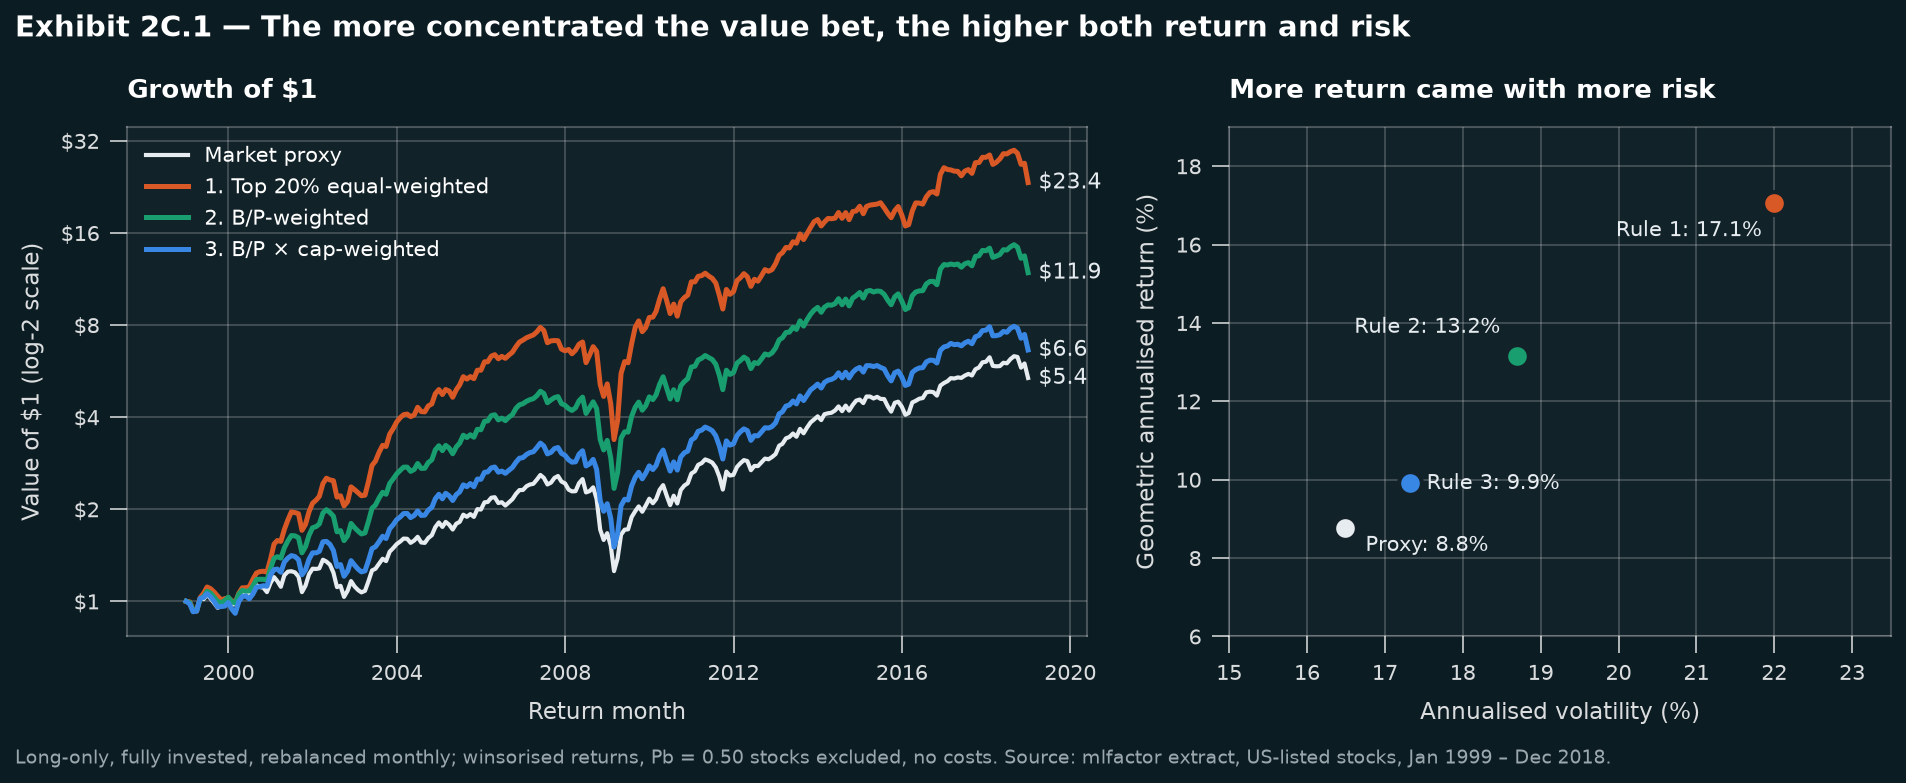

In [8]:
# Book-to-price exposure: reverse the provided P/B percentile, staying on the 0.01–1.00 grid
window["eligible"] = window["Pb"].ne(0.5)   # Pb = 0.50 rows carry no usable valuation signal
window["bp"] = 1.01 - window["Pb"]
window["w_p1"] = (window["Pb"].le(0.20) & window["eligible"]).astype(float)
window["w_p2"] = window["bp"] * window["eligible"]
window["w_p3"] = window["bp"] * window["Mkt_Cap_3M_Usd"] * window["eligible"]

LABELS = {"Market proxy": "Market proxy", "w_p1": "1. Top 20% equal-weighted", "w_p2": "2. B/P-weighted",
          "w_p3": "3. B/P × cap-weighted"}
COLOURS = {"Market proxy": C["proxy"], "1. Top 20% equal-weighted": C["p1"], "2. B/P-weighted": C["p2"],
           "3. B/P × cap-weighted": C["p3"]}
STRATEGIES = list(LABELS.values())[1:]

returns = pd.DataFrame({LABELS[w]: portfolio_return(window, w) for w in ["w_p1", "w_p2", "w_p3"]})
returns.insert(0, "Market proxy", proxy)
perf = performance(returns, ff3["RF"])
perf["Return vs proxy"] = perf["Geometric return"] - perf.loc["Market proxy", "Geometric return"]
perf["Vol vs proxy"] = perf["Volatility"] - perf.loc["Market proxy", "Volatility"]
display(perf.style.format({"Geometric return": "{:.1%}", "Arithmetic return": "{:.1%}", "Volatility": "{:.1%}",
                           "Sharpe (arithmetic)": "{:.2f}", "Max drawdown": "{:.1%}", "Return vs proxy": "{:+.1%}",
                           "Vol vs proxy": "{:+.1%}"}).set_caption(
    "Table 2C.1 — Long-only value portfolios vs the market proxy, winsorised returns, Jan 1999 – Dec 2018."))

sub_value = pd.DataFrame({label: (1 + returns.loc[a:b]).prod() ** (12 / len(returns.loc[a:b])) - 1
                          for label, (a, b) in sub_periods.items()})
display(sub_value.style.format("{:.1%}").set_caption("Table 2C.2 — Geometric annualised return by sub-period."))

# Sensitivity to the two cleaning choices
treatments = {
    "Exclude all Pb = 0.50 (base)": window["Pb"].ne(0.5),
    "Exclude Pb = 0.50 with Bv ≤ 0.05": ~(window["Pb"].eq(0.5) & window["Bv"].le(0.05)),
    "Keep Pb = 0.50 as a median stock": pd.Series(True, index=window.index),
}
rows = {}
for name, keep in treatments.items():
    for ret, ret_label in [("ret", "winsorised"), ("R1M_Usd", "raw")]:
        trial = window.assign(t1=(window["Pb"].le(0.20) & keep).astype(float), t2=window["bp"] * keep,
                              t3=window["bp"] * window["Mkt_Cap_3M_Usd"] * keep)
        frame = pd.DataFrame({LABELS[f"w_p{i}"]: portfolio_return(trial, f"t{i}", ret) for i in (1, 2, 3)})
        rows[(name, ret_label)] = (1 + frame).prod() ** (12 / len(frame)) - 1
display(pd.DataFrame(rows).T.style.format("{:.1%}").set_caption(
    "Table 2C.3 — Geometric annualised return under alternative cleaning choices."))
print(f"Market proxy, raw returns: {(1 + proxy_raw).prod() ** (12 / len(proxy_raw)) - 1:.1%}")

# Exhibit 2C.1 — what each construction earned, and at what risk
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.0), gridspec_kw={"width_ratios": [1.45, 1]})
for name in returns:
    wealth = growth_of_one(returns[name])
    axes[0].plot(wealth.index, wealth, color=COLOURS[name], lw=2.4 if name != "Market proxy" else 2.0, label=name)
    axes[0].annotate(f"${wealth.iloc[-1]:.1f}", xy=(wealth.index[-1], wealth.iloc[-1]), xytext=(5, 0),
                     textcoords="offset points", color="#E6ECEF", fontsize=10.5, va="center")
axes[0].set_yscale("log", base=2)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
axes[0].set_ylabel("Value of $1 (log-2 scale)")
axes[0].set_xlabel("Return month")
axes[0].set_title("Growth of $1", loc="left", fontsize=12.5)
axes[0].legend(loc="upper left")
axes[0].margins(x=0.07)
offsets = {"Market proxy": (10, -11), "1. Top 20% equal-weighted": (-6, -16), "2. B/P-weighted": (-8, 11), "3. B/P × cap-weighted": (8, -3)}
aligns = {"Market proxy": "left", "1. Top 20% equal-weighted": "right", "2. B/P-weighted": "right", "3. B/P × cap-weighted": "left"}
for name, row in perf.iterrows():
    axes[1].scatter(row["Volatility"] * 100, row["Geometric return"] * 100, s=120, color=COLOURS[name],
                    edgecolor=PANEL, lw=2, zorder=4)
    axes[1].annotate(f"{'Rule ' + name[0] if name[0].isdigit() else 'Proxy'}: {row['Geometric return']:.1%}",
                     xy=(row["Volatility"] * 100, row["Geometric return"] * 100), xytext=offsets[name],
                     textcoords="offset points", ha=aligns[name], color="#E6ECEF", fontsize=10)
axes[1].set_xlim(15, 23.5)
axes[1].set_ylim(6, 19)
axes[1].set_xlabel("Annualised volatility (%)")
axes[1].set_ylabel("Geometric annualised return (%)")
axes[1].set_title("More return came with more risk", loc="left", fontsize=12.5)
fig.suptitle("Exhibit 2C.1 — The more concentrated the value bet, the higher both return and risk", fontsize=14,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Long-only, fully invested, rebalanced monthly; winsorised returns, Pb = 0.50 stocks excluded, no costs. "
                 "Source: mlfactor extract, US-listed stocks, Jan 1999 – Dec 2018.", y=0.0)
save_exhibit(fig, "2c_value_performance")

,Stocks held,Largest weight %,Top 10 weight %,Effective stocks (1/Σw²)
Market proxy,1109,0.182,1.82,826
1. Top 20% equal-weighted,229,0.437,4.37,229
2. B/P-weighted,1057,0.185,1.85,797
3. B/P × cap-weighted,1057,0.395,3.77,616


Top holding of rule 3: {'Pb': 0.06, 'Mkt_Cap_3M_Usd': 0.98}; Corr(bp, cap) among eligible: -0.38


,Market cap percentile,P/B percentile,3-year volatility percentile
Market proxy,0.67,0.55,0.45
1. Top 20% equal-weighted,0.37,0.10,0.53
2. B/P-weighted,0.45,0.33,0.49
3. B/P × cap-weighted,0.63,0.38,0.44


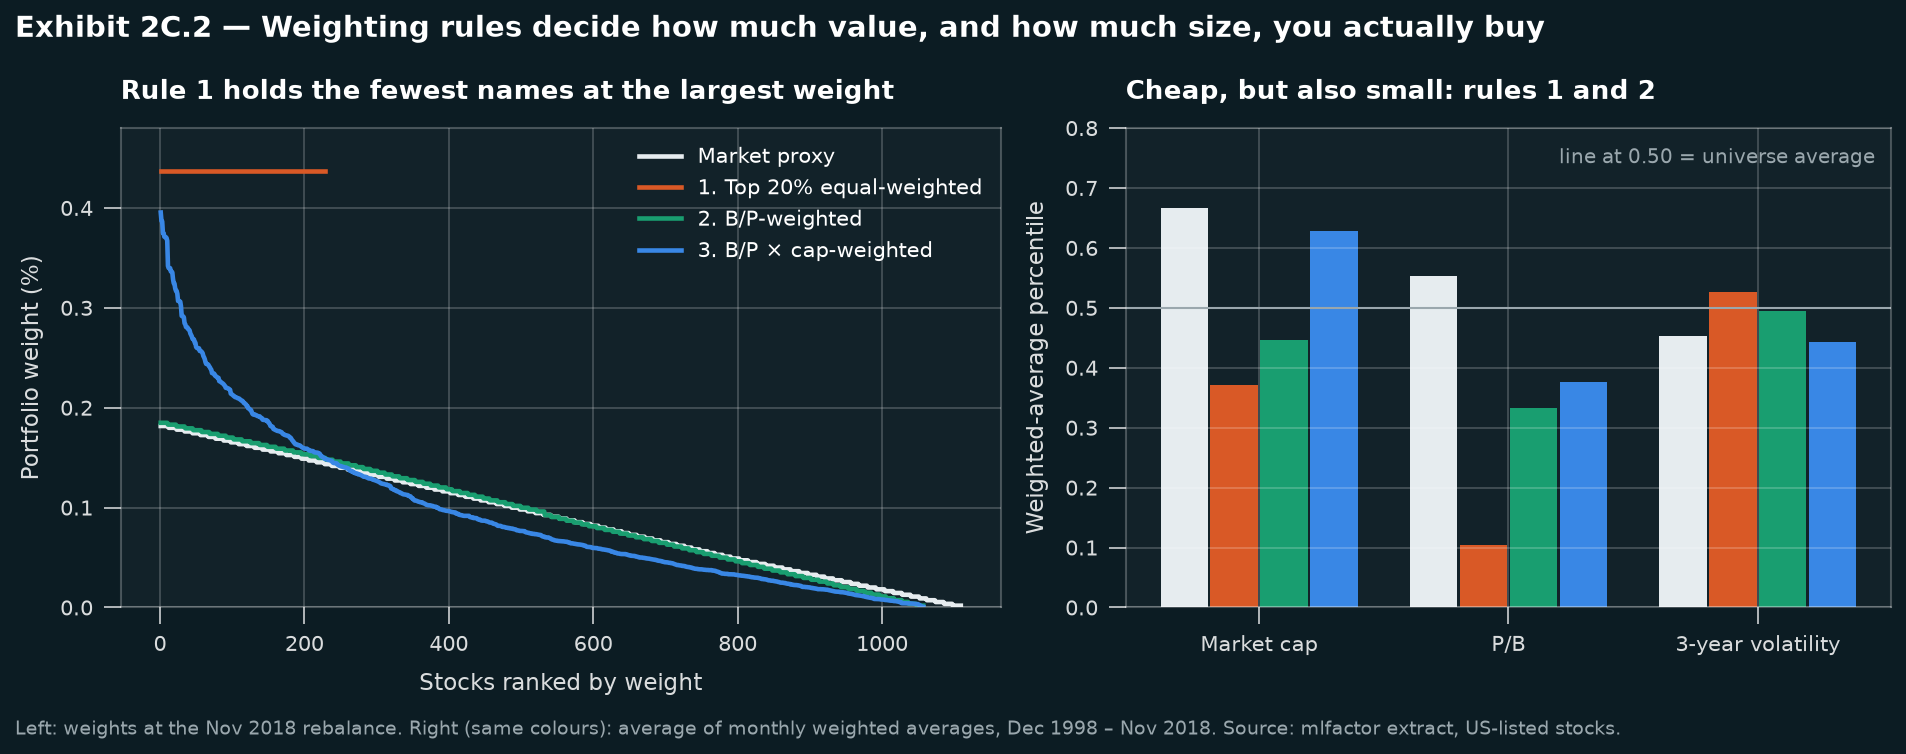

In [9]:
# Holdings as of the last rebalance (Nov 2018) and average portfolio characteristics
last = window[window["date"].eq(pd.Period("2018-11"))]
WEIGHT_COLS = {"Market proxy": "w_market", **{LABELS[w]: w for w in ["w_p1", "w_p2", "w_p3"]}}
holdings = {}
sorted_weights = {}
for name, col in WEIGHT_COLS.items():
    weights = last[col] / last[col].sum()
    held = weights[weights > 0]
    sorted_weights[name] = held.sort_values(ascending=False).to_numpy() * 100
    holdings[name] = {"Stocks held": len(held), "Largest weight %": held.max() * 100, "Top 10 weight %": held.nlargest(10).sum() * 100,
                      "Effective stocks (1/Σw²)": 1 / (held ** 2).sum()}
display(pd.DataFrame(holdings).T.style.format({"Stocks held": "{:.0f}", "Largest weight %": "{:.3f}", "Top 10 weight %": "{:.2f}",
                                               "Effective stocks (1/Σw²)": "{:.0f}"}).set_caption(
    f"Table 2C.4 — Portfolio shape at the Nov 2018 rebalance ({len(last)} stocks, {last['eligible'].sum()} eligible for value)."))
print(f"Top holding of rule 3: {last.loc[last['w_p3'].idxmax(), ['Pb', 'Mkt_Cap_3M_Usd']].to_dict()}; "
      f"Corr(bp, cap) among eligible: {last.loc[last['eligible'], 'bp'].corr(last.loc[last['eligible'], 'Mkt_Cap_3M_Usd']):.2f}")

traits = {"Mkt_Cap_3M_Usd": "Market cap percentile", "Pb": "P/B percentile", "Vol3Y_Usd": "3-year volatility percentile"}
portrait = {}
for name, col in WEIGHT_COLS.items():
    held = window[window[col] > 0]
    portrait[name] = {label: ((held[field] * held[col]).groupby(held["date"]).sum() / held[col].groupby(held["date"]).sum()).mean()
                      for field, label in traits.items()}
portrait = pd.DataFrame(portrait)
display(portrait.T.style.format("{:.2f}").set_caption("Table 2C.5 — Weighted-average characteristics, average over all months."))

# Exhibit 2C.2 — concentration and character
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
for name, weights in sorted_weights.items():
    axes[0].plot(np.arange(1, len(weights) + 1), weights, color=COLOURS[name], lw=2.2, label=name,
                 drawstyle="steps-post" if name.startswith("1") else "default")
axes[0].set_xlabel("Stocks ranked by weight")
axes[0].set_ylabel("Portfolio weight (%)")
axes[0].set_ylim(0, 0.48)
axes[0].set_title("Rule 1 holds the fewest names at the largest weight", loc="left", fontsize=12.5)
axes[0].legend(loc="upper right")
names = list(portrait.columns)
bar_width = 0.19
for i, name in enumerate(names):
    positions = np.arange(len(portrait)) + (i - 1.5) * (bar_width + 0.01)
    axes[1].bar(positions, portrait[name], width=bar_width, color=COLOURS[name])
axes[1].axhline(0.5, color=MUTED, lw=1.0)
axes[1].text(2.47, 0.75, "line at 0.50 = universe average", color=MUTED, fontsize=9.5, ha="right", va="center")
axes[1].set_xticks(np.arange(len(portrait)), ["Market cap", "P/B", "3-year volatility"])
axes[1].set_ylabel("Weighted-average percentile")
axes[1].set_ylim(0, 0.8)
axes[1].set_title("Cheap, but also small: rules 1 and 2", loc="left", fontsize=12.5)
fig.suptitle("Exhibit 2C.2 — Weighting rules decide how much value, and how much size, you actually buy",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Left: weights at the Nov 2018 rebalance. Right (same colours): average of monthly weighted averages, Dec 1998 – Nov 2018. "
                 "Source: mlfactor extract, US-listed stocks.", y=0.0)
save_exhibit(fig, "2c_holdings")

**Comment — return.** Rule 1 is highest at **17.1%/yr**, then rule 2 at 13.2%, rule 3 at 9.9% and the proxy at 8.8%. Rule 1 holds the deepest value (average Pb 0.10 against 0.55) and also much smaller stocks (cap percentile 0.37 against 0.67), so it collects both premia, as the SMB and HML loadings in Table 2D.3 confirm.

Three cautions apply:
* Most of the gap was earned early: 27.9% against 11.1% in 1999–2006, but 10.7% against 10.0% in 2013–18, when rules 2 and 3 fell just behind the proxy.
* Survivorship flatters this corner most, because cheap distressed firms that failed are largely missing.
* No trading costs are deducted, and the outcome is sensitive to cleaning: on raw returns rule 1 earns 24.5%, so 7.4 points a year depend on monthly outliers.

**Comment — risk.** Rule 1 also has the highest volatility at **22.0%**, against 18.7%, 17.3% and 16.5% for rule 2, rule 3 and the proxy. It is the least diversified portfolio, with 229 stocks that are smaller and more volatile than the market. Its extra return still more than paid for the extra risk historically (Sharpe 0.75 against 0.49 using arithmetic returns, 0.70 against 0.43 using geometric), subject to the same cautions.

**Comment — holdings (November 2018).** Rule 1 has both the fewest stocks (229, against 1,057 for rules 2 and 3) and the highest single-stock weight (0.44%, against 0.40% for rule 3 and 0.19% for rule 2).

The stock count is as expected: a cut-off drops 80% of the universe, while a tilt keeps every eligible name. The largest weight is closer, and less obvious. Multiplying by cap would normally make rule 3 the most concentrated, as cap-weighted portfolios are dominated by their largest names. Here percentile caps top out at 1.00, and few stocks are both large and cheap (correlation between B/P and cap −0.38). With true market caps, rule 3's largest weights would be much larger.

## 2D · Tracking error and similarity to HML

> **Question.** Compute each strategy's monthly excess return over the cap-weighted proxy, its annualised tracking error, and the correlations of these excess returns with each other and with Fama-French HML. Are they all investing in the same style factor, and which is closest to HML?

The panel returns are already labelled by the month earned, so HML is matched on that same month.

,Average excess %/yr,Tracking error %/yr,Information ratio
1. Top 20% equal-weighted,8.41,9.46,0.89
2. B/P-weighted,4.37,4.94,0.88
3. B/P × cap-weighted,1.20,2.86,0.42


,1. Top 20% equal-weighted,2. B/P-weighted,3. B/P × cap-weighted,FF HML
1. Top 20% equal-weighted,1.00,0.96,0.74,0.56
2. B/P-weighted,0.96,1.00,0.76,0.60
3. B/P × cap-weighted,0.74,0.76,1.00,0.85
FF HML,0.56,0.60,0.85,1.00


On raw returns: tracking error %/yr {'1. Top 20% equal-weighted': 11.32, '2. B/P-weighted': 5.51, '3. B/P × cap-weighted': 3.13}
On raw returns: correlation with HML {'1. Top 20% equal-weighted': 0.48, '2. B/P-weighted': 0.54, '3. B/P × cap-weighted': 0.82}


,Alpha %/yr,Mkt-RF,SMB,HML,t const,t Mkt-RF,t SMB,t HML,R2
1. Top 20% equal-weighted,5.68,0.07,0.40,0.60,4.03,2.52,10.72,15.79,0.57
2. B/P-weighted,2.97,-0.00,0.24,0.34,4.58,-0.12,14.33,19.23,0.67
3. B/P × cap-weighted,0.75,-0.00,0.02,0.23,2.26,-0.37,2.65,25.46,0.74


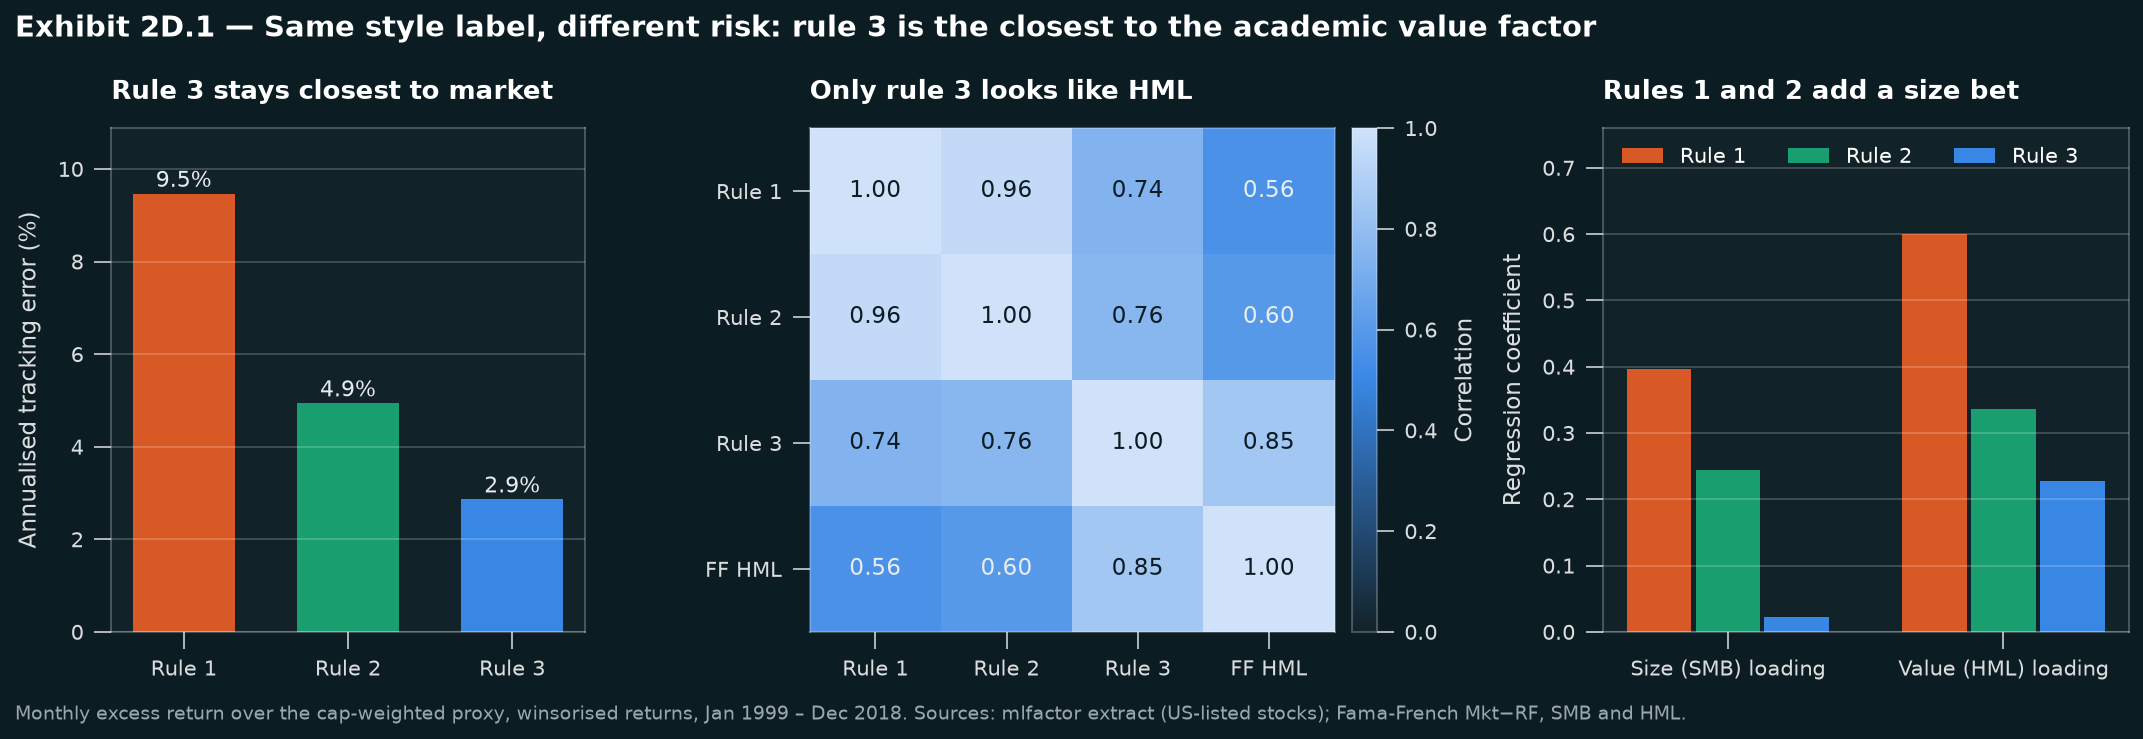

In [10]:
# Excess return of each strategy over the market proxy; HML is already labelled by its return month
excess = returns[STRATEGIES].sub(returns["Market proxy"], axis=0)
hml = ff3["HML"].reindex(excess.index)
tracking = pd.DataFrame({
    "Average excess %/yr": excess.mean() * 1200,
    "Tracking error %/yr": excess.std(ddof=1) * np.sqrt(12) * 100,
    "Information ratio": excess.mean() * 12 / (excess.std(ddof=1) * np.sqrt(12)),
})
display(tracking.style.format("{:.2f}").set_caption(
    "Table 2D.1 — Excess return over the cap-weighted proxy, Jan 1999 – Dec 2018."))

correlations = excess.join(hml.rename("FF HML")).corr()
display(correlations.style.format("{:.2f}").set_caption(
    "Table 2D.2 — Correlation of excess returns with each other and with FF HML."))

raw_returns = pd.DataFrame({LABELS[w]: portfolio_return(window, w, "R1M_Usd") for w in ["w_p1", "w_p2", "w_p3"]})
raw_excess = raw_returns.sub(proxy_raw, axis=0)
print("On raw returns: tracking error %/yr", (raw_excess.std() * np.sqrt(12) * 100).round(2).to_dict())
print("On raw returns: correlation with HML", raw_excess.corrwith(hml).round(2).to_dict())

factors = sm.add_constant(ff3[["Mkt-RF", "SMB", "HML"]].reindex(excess.index))
fits = {name: sm.OLS(excess[name], factors).fit() for name in STRATEGIES}
loadings = pd.DataFrame({name: fit.params for name, fit in fits.items()}).T
loadings["const"] *= 1200
t_stats = pd.DataFrame({name: fit.tvalues for name, fit in fits.items()}).T.add_prefix("t ")
display(loadings.rename(columns={"const": "Alpha %/yr"}).join(t_stats).assign(
    R2=[fit.rsquared for fit in fits.values()]).style.format("{:.2f}").set_caption(
    "Table 2D.3 — Excess return regressed on the FF3 factors (OLS t-statistics)."))

# Exhibit 2D.1 — risk against the benchmark, kinship with HML, and why they differ
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.7), gridspec_kw={"width_ratios": [0.9, 1.08, 1]})
short = ["Rule 1", "Rule 2", "Rule 3"]
te_values = tracking["Tracking error %/yr"]
axes[0].bar(short, te_values, width=0.62, color=[COLOURS[s] for s in STRATEGIES])
for i, value in enumerate(te_values):
    axes[0].text(i, value + 0.15, f"{value:.1f}%", ha="center", color="#E6ECEF", fontsize=10.5)
axes[0].set_ylabel("Annualised tracking error (%)")
axes[0].set_ylim(0, te_values.max() * 1.15)
axes[0].set_title("Rule 3 stays closest to market", loc="left", fontsize=12.5)
axes[0].grid(axis="x", visible=False)

labels = short + ["FF HML"]
image = axes[1].imshow(correlations, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
for i in range(4):
    for j in range(4):
        value = correlations.iloc[i, j]
        axes[1].text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=11,
                     color="#0C1C23" if value > 0.62 else "#E6ECEF")
axes[1].set_xticks(range(4), labels)
axes[1].set_yticks(range(4), labels)
axes[1].grid(False)
axes[1].set_title("Only rule 3 looks like HML", loc="left", fontsize=12.5)
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.03, label="Correlation")

positions = np.arange(2)
for i, strategy in enumerate(STRATEGIES):
    axes[2].bar(positions + (i - 1) * 0.25, loadings.loc[strategy, ["SMB", "HML"]], width=0.235,
                color=COLOURS[strategy], label=short[i])
axes[2].set_xticks(positions, ["Size (SMB) loading", "Value (HML) loading"])
axes[2].set_ylabel("Regression coefficient")
axes[2].set_title("Rules 1 and 2 add a size bet", loc="left", fontsize=12.5)
axes[2].legend(loc="upper left", ncol=3)
axes[2].set_ylim(0, 0.76)
axes[2].grid(axis="x", visible=False)
fig.suptitle("Exhibit 2D.1 — Same style label, different risk: rule 3 is the closest to the academic value factor",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
source_note(fig, "Monthly excess return over the cap-weighted proxy, winsorised returns, Jan 1999 – Dec 2018. Sources: mlfactor "
                 "extract (US-listed stocks); Fama-French Mkt−RF, SMB and HML.", y=0.0)
save_exhibit(fig, "2d_tracking_and_hml")

**Comment — tracking error.** Rule 3 is lowest at **2.9%**, against 4.9% for rule 2 and 9.5% for rule 1. It keeps the market's cap tilt and changes weights only through B/P, so its average size stays close to the proxy (cap percentile 0.63 against 0.67). Rule 2 removes the cap link, and rule 1 also discards 80% of the names.

**Comment — correlations.** All are clearly positive, so all three are recognisably value strategies, but they are not the same investment. Rules 1 and 2 are near-duplicates (0.96), while rule 3 correlates about 0.75 with each. The regressions show why: rules 1 and 2 add a large size bet (SMB loadings of 0.40 and 0.24, *t* of 10.7 and 14.3), while rule 3 has almost none (0.02).

**Comment — closest to HML.** Rule 3 is most similar at **0.85**, against 0.60 for rule 2 and 0.56 for rule 1, and the ranking is the same on raw returns (0.82, 0.54, 0.48). This is as expected. HML weights stocks by market cap inside its portfolios and averages small and big portfolios on both sides, so it takes almost no net size bet. Rule 3 is the only rule that keeps cap weighting, and its near-zero SMB loading shows the same size neutrality.

The correlation stays below 1 because HML is long/short, uses NYSE breakpoints at 30% and 70%, rebalances once a year and has a wider universe. The positive regression alphas (5.7%, 3.0% and 0.8%/yr) should not be read as skill, given survivorship and the absence of costs.

## Conclusion

1. **Check the data before testing an idea.** Date alignment, the reversed P/B direction, filled P/B values and extreme returns would each have distorted the results without an error message.
2. **The panel is good for co-movement, weaker for return levels.** Timing and correlation checks are strong, but survivorship and flat rank-based weights lift returns above any investable benchmark.
3. **"Value" is a family of portfolios.** The same signal gave tracking errors from 2.9% to 9.5% and HML correlations from 0.56 to 0.85. The more a rule departs from cap weights, the more it adds a small-cap bet on top of value.
4. **The trade-off is return against benchmark risk and capacity.** Rule 1 had the highest historical return but is concentrated in small stocks, and its result is the most exposed to survivorship, cleaning choices and costs. Rule 3 gave up return for a purer value exposure that stays close to the market.